# 06 · Feature Engineering nâng cao & Traditional ML

Notebook này **hiện thực hóa các đề xuất cải tiến** trong báo cáo [`ML_Pipeline_Analysis.md`](../ML_Pipeline_Analysis.md) và **không chỉnh sửa** bất kỳ notebook cũ nào (01 → 05). Các notebook cũ được giữ nguyên làm baseline đối chứng.

**Phạm vi thuật toán:** chỉ dùng **Machine Learning truyền thống**: Logistic Regression, Random Forest, Histogram Gradient Boosting (thuật toán cùng họ với LightGBM, có sẵn trong scikit-learn), XGBoost, Stacking và Soft Voting. Notebook **không dùng** Deep Learning hay Transformer/LLM.

| Vấn đề trong báo cáo | Cách xử lý trong notebook | Mục |
|---|---|:-:|
| Train/serve skew (scheme, `www.`, `/` cuối) và shortcut "không có `/` ⇒ phishing" | Hàm `normalize_url()` dùng chung cho cả train lẫn inference | §3 |
| Trùng lặp gần đúng, nhãn mâu thuẫn | Khử trùng lặp **sau** chuẩn hóa, loại URL mâu thuẫn nhãn | §4 |
| Rò rỉ domain giữa train/test (76.6%) | `StratifiedGroupKFold` theo *registered domain*, chia Train/Val/Test = 70/10/20 | §6 |
| Đặc trưng nghèo (23% vector mơ hồ) | ~60 đặc trưng mới (entropy, brand-mismatch, typosquatting, TLD target-encoding…) và **TF-IDF char n-gram** | §7, §11 |
| Đặc trưng chết, auto-discovery dễ vỡ | Định nghĩa tường minh, loại cột hằng số | §7, §12 |
| Mất cân bằng lớp (3.44 : 1) | `class_weight='balanced'`, `scale_pos_weight` | §11–§14 |
| Tuning chạm biên, chấm theo F1 | Optuna (TPE) với không gian rộng, early stopping, tối ưu **PR-AUC** | §13 |
| Ngưỡng cố định 0.5 | Chọn ngưỡng trên **validation**, chỉ chạm test **một lần** | §9 |

> ⏱️ Thời gian chạy toàn bộ khoảng 15–25 phút trên CPU 8 nhân (phần lớn dành cho TF-IDF, stacking OOF và Optuna). Có thể giảm `N_OPTUNA_TRIALS` ở cell cấu hình để chạy nhanh hơn.

## 1. Imports và cấu hình

Nạp thư viện và khai báo các hằng số cấu hình dùng xuyên suốt notebook. Thư mục gốc dự án được **tự động dò tìm**, nên notebook chạy đúng dù khởi động Jupyter ở thư mục gốc hay trong `notebooks/` (notebook cũ gặp lỗi đường dẫn ở điểm này).

In [1]:
import sys
import re
import math
import time
import warnings
import ipaddress
from pathlib import Path
from collections import Counter
from functools import lru_cache
from urllib.parse import urlsplit

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tldextract
import joblib
import optuna
from scipy import sparse
from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import TargetEncoder
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

warnings.filterwarnings('ignore', category=FutureWarning)


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Đi ngược lên cây thư mục cho tới khi thấy data/raw/phishing_site_urls.csv."""
    for p in [start, *start.parents]:
        if (p / 'data' / 'raw' / 'phishing_site_urls.csv').exists():
            return p
    raise FileNotFoundError('Không tìm thấy thư mục gốc dự án (data/raw/phishing_site_urls.csv).')


ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Hàm đặc trưng CŨ, chỉ dùng để tái lập baseline (§10)
from src.features import lexical_features, host_features

# ----------------------------- CẤU HÌNH ---------------------------------
RAW_PATH = ROOT / 'data' / 'raw' / 'phishing_site_urls.csv'
MODEL_DIR = ROOT / 'models'
RANDOM_STATE = 42
N_OPTUNA_TRIALS = 20          # số cấu hình Optuna thử cho XGBoost
OPTUNA_TIMEOUT = 900          # giới hạn thời gian tuning (giây)
PLOT_SAMPLE = 100_000         # số mẫu (từ tập train) dùng để vẽ EDA
SAVE_ARTIFACTS = True         # lưu mô hình và bảng metrics vào models/
LABELS = ['Legitimate', 'Phishing']
PALETTE = {'Legitimate': '#2b8cbe', 'Phishing': '#e34a33'}

np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
optuna.logging.set_verbosity(optuna.logging.WARNING)
print(f'Project root : {ROOT}')
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}')

Project root : /Users/buiquanghuy/Documents/phishing-url-detection
Python 3.14.4 | pandas 3.0.5 | numpy 2.5.2


## 2. Tải dữ liệu thô

Notebook đọc lại **dữ liệu thô** thay vì `dataset_processed.csv`, vì việc khử trùng lặp cần thực hiện **sau** khi chuẩn hóa URL (§4). Nhãn được mã hóa giống notebook cũ: `bad → 1` (Phishing), `good → 0` (Legitimate).

In [2]:
raw = pd.read_csv(RAW_PATH)
raw = raw.rename(columns={'URL': 'url', 'Label': 'label_text'})
raw['label'] = raw['label_text'].map({'bad': 1, 'good': 0})
raw = raw.dropna(subset=['url', 'label']).drop(columns='label_text')
raw['url'] = raw['url'].astype(str)
raw['label'] = raw['label'].astype(int)

print(f'Số dòng dữ liệu thô: {len(raw):,}')
display(raw['label'].value_counts().rename(index={0: 'Legitimate (0)', 1: 'Phishing (1)'}).to_frame('count'))
display(raw.sample(5, random_state=RANDOM_STATE))

Số dòng dữ liệu thô: 549,346


,count
label,
Legitimate (0),392924
Phishing (1),156422


,url,label
452638,tubevector.com/search/?q=erika,0
306476,classmates.com/directory/school/Marian%20Chris...,0
100735,isgsi.com/office/adb/c58c94eccbfb951bd4ba5f2a6...,1
384460,manufacturersnews.com/executives.asp?start=CEN,0
40436,'9d345009-a-62cb3a1a-s-sites.googlegroups.com/...,1


## 3. Chuẩn hóa URL (Canonicalization)

Đây là bước sửa lỗi quan trọng nhất. Trong dữ liệu train, 99.98% URL **không có scheme**, còn URL hợp lệ thường có `/` ở cuối. Vì vậy mô hình cũ chấm `google.com` là **96.8% phishing**, và cùng một website có thể nhận xác suất từ 0.30 đến 0.985 tùy cách viết.

Các quy tắc chuẩn hóa (áp dụng **giống hệt** cho train và inference):
1. Bỏ scheme (`http://`, `https://`, `ftp://`…)
2. Viết thường phần host (tên miền không phân biệt hoa/thường)
3. Bỏ tiền tố `www.` / `www2.`…
4. Bỏ dấu `.` cuối FQDN (`google.com.`)
5. Bỏ mọi dấu `/` ở cuối URL

In [3]:
SCHEME_RE = re.compile(r'^[a-z][a-z0-9+.\-]*://', re.IGNORECASE)
WWW_RE = re.compile(r'^www\d{0,3}\.')
AUTHORITY_RE = re.compile(r'^([^/?#]*)(.*)$', re.DOTALL)   # authority | phần còn lại


def normalize_url(url) -> str:
    """Đưa URL về dạng chính tắc, dùng chung cho TRAIN và INFERENCE."""
    u = SCHEME_RE.sub('', str(url).strip())                 # (1) bỏ scheme
    authority, rest = AUTHORITY_RE.match(u).groups()
    authority = WWW_RE.sub('', authority.lower())           # (2) + (3)
    authority = authority.rstrip('.')                       # (4)
    return authority + rest.rstrip('/')                     # (5)


# Minh họa: các biến thể của cùng một website phải cho ra cùng một chuỗi
demo = ['google.com', 'https://google.com', 'www.google.com', 'https://www.google.com/',
        'HTTP://WWW.Google.com//', 'paypal.com.secure-login.xyz/webscr.php?cmd=_login']
display(pd.DataFrame({'URL gốc': demo, 'Sau chuẩn hóa': [normalize_url(u) for u in demo]}))

,URL gốc,Sau chuẩn hóa
0,google.com,google.com
1,https://google.com,google.com
2,www.google.com,google.com
3,https://www.google.com/,google.com
4,HTTP://WWW.Google.com//,google.com
5,paypal.com.secure-login.xyz/webscr.php?cmd=_login,paypal.com.secure-login.xyz/webscr.php?cmd=_login


## 4. Khử trùng lặp sau chuẩn hóa và loại nhãn mâu thuẫn

Notebook 01 chỉ khử trùng lặp theo chuỗi chính xác. Sau khi chuẩn hóa, các bản **gần trùng** (khác nhau ở `www.`, `/` cuối, chữ hoa…) sẽ lộ ra. Những URL chuẩn hóa mang **cả hai nhãn** bị loại hoàn toàn, vì chúng chỉ đưa nhiễu vào cả quá trình học lẫn đánh giá.

In [4]:
raw['url_norm'] = raw['url'].map(normalize_url)
n_raw = len(raw)
n_exact_dup = int(raw.duplicated(subset='url').sum())
raw = raw[raw['url_norm'].str.len() > 0]

# Số nhãn khác nhau trên mỗi URL chuẩn hóa
n_labels = raw.groupby('url_norm')['label'].transform('nunique')
conflict_rows = int((n_labels > 1).sum())
conflict_urls = raw.loc[n_labels > 1, 'url_norm'].nunique()

df = raw[n_labels == 1].drop_duplicates(subset='url_norm').reset_index(drop=True)

summary = pd.DataFrame({
    'Bước': ['Dữ liệu thô', 'Trùng lặp chính xác (notebook 01 đã xử lý)',
             'Sau khi khử trùng lặp chính xác (notebook 01)',
             f'Dòng thuộc {conflict_urls:,} URL chuẩn hóa mâu thuẫn nhãn (loại bỏ)',
             'Sau chuẩn hóa + khử trùng lặp + loại mâu thuẫn (notebook này)'],
    'Số dòng': [n_raw, n_exact_dup, n_raw - n_exact_dup, conflict_rows, len(df)],
})
display(summary)
print(f'Loại thêm {n_raw - n_exact_dup - len(df):,} bản gần trùng/mâu thuẫn so với notebook 01.')
display(df['label'].value_counts(normalize=True).rename(index={0: 'Legitimate', 1: 'Phishing'}).to_frame('tỉ lệ').round(4))

,Bước,Số dòng
0,Dữ liệu thô,549346
1,Trùng lặp chính xác (notebook 01 đã xử lý),42151
2,Sau khi khử trùng lặp chính xác (notebook 01),507195
3,Dòng thuộc 2 URL chuẩn hóa mâu thuẫn nhãn (loạ...,6
4,Sau chuẩn hóa + khử trùng lặp + loại mâu thuẫn...,501550


Loại thêm 5,645 bản gần trùng/mâu thuẫn so với notebook 01.


,tỉ lệ
label,
Legitimate,0.7833
Phishing,0.2167


## 5. Phân tách thành phần URL và Registered Domain

Mỗi URL được tách thành `host`, `port`, `path`, `query`. Sau đó `tldextract` (dùng **bản Public Suffix List đóng gói sẵn**, không cần mạng) tách host thành *subdomain*, *SLD*, *suffix* và **registered domain** (ví dụ `login.paypal.com.evil.co.uk` → `evil.co.uk`). Registered domain là **khóa nhóm** khi chia dữ liệu ở §6.

In [5]:
TLD_EXTRACT = tldextract.TLDExtract(suffix_list_urls=())   # offline, tái lập được


def split_components(url_norm: str):
    """Tách URL chuẩn hóa → (host, has_port, has_userinfo, path, query)."""
    try:
        parts = urlsplit('http://' + url_norm)
        has_port = parts.port is not None            # có thể ném ValueError nếu port sai định dạng
        return (parts.hostname or ''), int(has_port), int('@' in parts.netloc), parts.path, parts.query
    except ValueError:                               # URL dị dạng (IPv6 hỏng, port lỗi…) → tách thủ công
        authority, rest = AUTHORITY_RE.match(url_norm).groups()
        hostport = authority.rsplit('@', 1)[-1]
        path, _, query = rest.partition('?')
        return hostport.split(':')[0], int(':' in hostport), int('@' in authority), path, query


def host_parts(host: str):
    """Tách host → (subdomain, sld, suffix, registered_domain) theo Public Suffix List."""
    r = TLD_EXTRACT(host)
    # tldextract ≥ 5.3 đổi tên registered_domain → top_domain_under_public_suffix
    registered = (r.top_domain_under_public_suffix if hasattr(r, 'top_domain_under_public_suffix')
                  else r.registered_domain)
    return r.subdomain, r.domain, r.suffix, (registered or host)   # IP / host không có suffix → dùng host


t0 = time.time()
df['host'] = [split_components(u)[0] for u in df['url_norm']]
unique_hosts = df['host'].unique()
registered_map = {h: host_parts(h)[3] for h in unique_hosts}
df['registered_domain'] = df['host'].map(registered_map)
print(f'Đã xử lý {len(unique_hosts):,} host duy nhất trong {time.time() - t0:.1f}s')
print(f'Số registered domain duy nhất: {df["registered_domain"].nunique():,}')

top_domains = (df.groupby('registered_domain')['label']
                 .agg(n_urls='size', phishing_rate='mean')
                 .sort_values('n_urls', ascending=False).head(10))
display(top_domains.round(3))

Đã xử lý 187,611 host duy nhất trong 7.6s
Số registered domain duy nhất: 151,535


,n_urls,phishing_rate
registered_domain,,
wikipedia.org,13424,0.000
youtube.com,8632,0.000
facebook.com,8337,0.001
blogspot.com,7862,0.047
yahoo.com,5808,0.001
linkedin.com,5025,0.000
amazon.com,4764,0.000
imdb.com,3471,0.000
ietf.org,3212,0.000


## 6. Chia Train / Validation / Test theo domain (chống rò rỉ)

Notebook cũ chia ngẫu nhiên theo dòng, nên **76.6% mẫu test có domain đã xuất hiện trong train**. Mô hình vì vậy có thể "nhớ domain" thay vì học dấu hiệu phishing. Ở đây ta dùng `StratifiedGroupKFold`, vừa **giữ tỉ lệ nhãn** vừa đảm bảo **mỗi registered domain chỉ thuộc đúng một tập**:

| Tập | Tỉ lệ | Vai trò |
|---|:-:|---|
| Train | ~70% | Huấn luyện, fit TF-IDF / TargetEncoder |
| Validation | ~10% | Early stopping, Optuna, **chọn ngưỡng**, chọn trọng số ensemble |
| Test | ~20% | Đánh giá cuối, **chỉ dùng một lần** |

In [6]:
y_all = df['label'].to_numpy()
groups_all = df['registered_domain'].to_numpy()

# Tách 20% test (1/5 fold), rồi tách 1/8 phần còn lại làm validation (~10% tổng)
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
trval_idx, test_idx = next(outer.split(np.zeros(len(df)), y_all, groups_all))
inner = StratifiedGroupKFold(n_splits=8, shuffle=True, random_state=RANDOM_STATE)
tr_rel, val_rel = next(inner.split(np.zeros(len(trval_idx)), y_all[trval_idx], groups_all[trval_idx]))
train_idx, val_idx = trval_idx[tr_rel], trval_idx[val_rel]

y_train, y_val, y_test = y_all[train_idx], y_all[val_idx], y_all[test_idx]
groups_train = groups_all[train_idx]

# Kiểm tra: không domain nào xuất hiện ở hai tập khác nhau
g_tr, g_val, g_te = set(groups_all[train_idx]), set(groups_all[val_idx]), set(groups_all[test_idx])
assert not (g_tr & g_te) and not (g_tr & g_val) and not (g_val & g_te), 'Rò rỉ domain giữa các tập!'

split_info = pd.DataFrame({
    'Số URL': [len(train_idx), len(val_idx), len(test_idx)],
    'Tỉ lệ (%)': np.round(np.array([len(train_idx), len(val_idx), len(test_idx)]) / len(df) * 100, 1),
    'Số domain': [len(g_tr), len(g_val), len(g_te)],
    'Tỉ lệ phishing': [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=['Train', 'Validation', 'Test'])
display(split_info.round(4))
print('✅ Không có domain nào dùng chung giữa Train / Validation / Test.')

,Số URL,Tỉ lệ (%),Số domain,Tỉ lệ phishing
Train,351090,70.0,106056,0.2167
Validation,50153,10.0,15156,0.2167
Test,100307,20.0,30323,0.2167


✅ Không có domain nào dùng chung giữa Train / Validation / Test.


## 7. Feature Engineering nâng cao

Bộ đặc trưng mới thay thế 20 đặc trưng cũ. Tất cả được tính trên **URL đã chuẩn hóa**, và mỗi đặc trưng nhắm tới một kỹ thuật tấn công cụ thể:

| Nhóm | Đặc trưng tiêu biểu | Mối đe dọa mục tiêu |
|---|---|---|
| Cấu trúc | `url_len`, `path_depth`, `n_params`, `query_len`, tỉ lệ chữ/số/ký tự đặc biệt | Hình thái URL tổng quát |
| Ngẫu nhiên tính | `host_entropy`, `sld_entropy`, `sld_vowel_ratio`, `sld_max_consonant_run` | Domain sinh tự động (DGA) |
| Thương hiệu | `brand_out_of_domain`, `brand_in_subdomain`, `brand_combo_sld`, `sld_is_brand` | Brand impersonation, combosquatting |
| Typosquatting | `typosquat_dist`, `is_typosquat` (Levenshtein tới danh sách brand) | `paypa1.com`, `gooogle.com` |
| Từ khóa theo vị trí | `sens_in_host`, `sens_in_path` (so khớp theo **ranh giới từ**) | Giảm FP kiểu `author` khớp `auth` |
| Né tránh | `host_is_ip` (gồm IPv6/hex/số nguyên), `host_has_punycode`, `has_userinfo` (`@`), `has_port`, `is_shortener` | Che giấu đích đến |
| Payload | `ext_executable`, `ext_script`, `ext_archive`, `has_embedded_url`, `has_redirect_param`, `double_slash_in_path` | Phát tán mã độc, open redirect |
| TLD | `tld` → **Target Encoding** (cross-fitted) | Mỗi TLD có mức rủi ro riêng |

### 7.1. Từ điển tri thức (brand, từ khóa, URL shortener, đuôi file)

In [7]:
# Thương hiệu hay bị giả mạo (chỉ giữ tên ≥ 4 ký tự để tránh khớp nhầm: 'ups', 'irs', 'aol'…)
BRANDS = ['paypal', 'apple', 'icloud', 'itunes', 'microsoft', 'office365', 'outlook', 'hotmail',
          'google', 'gmail', 'facebook', 'instagram', 'whatsapp', 'amazon', 'netflix', 'ebay',
          'chase', 'wellsfargo', 'bankofamerica', 'citibank', 'hsbc', 'barclays', 'santander',
          'dropbox', 'docusign', 'adobe', 'yahoo', 'linkedin', 'twitter', 'usaa', 'americanexpress',
          'amex', 'alibaba', 'fedex', 'mastercard', 'coinbase', 'binance', 'blockchain', 'bitcoin']
BRAND_SET = set(BRANDS)
TYPO_BRANDS = [b for b in BRANDS if len(b) >= 5]        # brand đủ dài mới xét typosquatting
# Ranh giới trái: brand không được đứng sau một chữ cái (tránh 'pineapple' → 'apple')
BRAND_RE = re.compile(r'(?<![a-z])(' + '|'.join(sorted(BRANDS, key=len, reverse=True)) + ')')

# Từ khóa lừa đảo, so khớp theo ranh giới từ ở cả hai phía
SENSITIVE_WORDS = ['login', 'log-in', 'logon', 'signin', 'sign-in', 'verify', 'verification', 'validate',
                   'account', 'update', 'confirm', 'secure', 'security', 'banking', 'password', 'passwd',
                   'webscr', 'cmd', 'ebayisapi', 'wallet', 'suspend', 'suspended', 'unlock', 'billing',
                   'invoice', 'recover', 'recovery', 'authenticate', 'authorize', 'credential', 'restore']
SENSITIVE_RE = re.compile(r'(?<![a-z])(?:' + '|'.join(map(re.escape, SENSITIVE_WORDS)) + r')(?![a-z])')

SHORTENERS = {'bit.ly', 'goo.gl', 'tinyurl.com', 't.co', 'ow.ly', 'is.gd', 'buff.ly', 'adf.ly', 'bit.do',
              'cutt.ly', 'shorturl.at', 'rebrand.ly', 'tiny.cc', 'rb.gy', 'x.co', 'lnkd.in', 'db.tt',
              'qr.net', '1url.com', 'tr.im', 'v.gd', 'tinyurl.co', 'shorte.st', 'soo.gd'}

EXT_GROUPS = {
    'ext_executable': {'exe', 'scr', 'bat', 'msi', 'apk', 'jar', 'dll', 'bin', 'vbs', 'ps1', 'cmd'},
    'ext_script':     {'php', 'asp', 'aspx', 'jsp', 'cgi', 'pl', 'py'},
    'ext_html':       {'html', 'htm', 'shtml', 'xhtml'},
    'ext_archive':    {'zip', 'rar', '7z', 'gz', 'tar', 'tgz'},
    'ext_document':   {'pdf', 'doc', 'docx', 'xls', 'xlsx', 'ppt', 'rtf'},
}

TOKEN_SPLIT_RE = re.compile(r'[^a-z0-9]+')
EXT_RE = re.compile(r'[a-z0-9]{1,5}')
EMBED_RE = re.compile(r'(?:https?:|https?%3a|www\.)')                     # URL lồng trong path/query
REDIRECT_RE = re.compile(r'(?:^|[&;])(?:url|redirect|redir|next|goto|return|returnurl|dest|destination|'
                         r'continue|target|link|out)=')
IP_LIKE_RE = re.compile(r'(?:0x[0-9a-f]+|\d+)(?:\.(?:0x[0-9a-f]+|\d+)){0,3}')   # 3232235777, 0xC0A80001…
VOWELS = set('aeiou')
print(f'{len(BRANDS)} brand | {len(SENSITIVE_WORDS)} từ khóa | {len(SHORTENERS)} shortener')

39 brand | 31 từ khóa | 24 shortener


### 7.2. Hàm tiện ích: entropy, Levenshtein, phát hiện IP

In [8]:
def shannon_entropy(s: str) -> float:
    """Entropy Shannon (bit/ký tự). Chuỗi ngẫu nhiên kiểu DGA có entropy cao."""
    if not s:
        return 0.0
    n = len(s)
    return -sum(c / n * math.log2(c / n) for c in Counter(s).values())


def vowel_ratio(s: str) -> float:
    letters = [c for c in s if c.isalpha()]
    return sum(c in VOWELS for c in letters) / len(letters) if letters else 0.0


def max_consonant_run(s: str) -> int:
    """Độ dài chuỗi phụ âm liên tiếp dài nhất (domain 'không phát âm được')."""
    best = run = 0
    for c in s:
        run = run + 1 if (c.isalpha() and c not in VOWELS) else 0
        best = max(best, run)
    return best


def bounded_levenshtein(a: str, b: str, max_d: int = 3) -> int:
    """Khoảng cách Levenshtein, dừng sớm khi vượt max_d (trả về max_d)."""
    if abs(len(a) - len(b)) >= max_d:
        return max_d
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        if min(cur) >= max_d:
            return max_d
        prev = cur
    return min(prev[-1], max_d)


@lru_cache(maxsize=None)
def typosquat_info(sld: str):
    """(khoảng cách nhỏ nhất tới brand [0..3], cờ typosquat). Cache theo SLD để tăng tốc."""
    if len(sld) < 4:
        return 3, 0
    best, flag = 3, 0
    for b in TYPO_BRANDS:
        d = bounded_levenshtein(sld, b)
        best = min(best, d)
        if 1 <= d <= (1 if len(b) <= 6 else 2):   # gần giống nhưng KHÔNG trùng brand
            flag = 1
    return best, flag


def is_ip_host(host: str) -> bool:
    """IPv4/IPv6 chuẩn và các dạng né tránh (số nguyên, hex, octal)."""
    if not host:
        return False
    h = host.strip('[]')
    try:
        ipaddress.ip_address(h)
        return True
    except ValueError:
        return bool(IP_LIKE_RE.fullmatch(h))


# Kiểm thử nhanh
print('entropy(google)        =', round(shannon_entropy('google'), 3))
print('entropy(rsblnytiseayj) =', round(shannon_entropy('rsblnytiseayj'), 3))
print('typosquat(paypa1)      =', typosquat_info('paypa1'))
print('typosquat(paypal)      =', typosquat_info('paypal'))
print('IP 3232235777 / 0xC0A80001 / ::1 :', is_ip_host('3232235777'), is_ip_host('0xc0a80001'), is_ip_host('::1'))

entropy(google)        = 1.918
entropy(rsblnytiseayj) = 3.393
typosquat(paypa1)      = (1, 1)
typosquat(paypal)      = (0, 0)
IP 3232235777 / 0xC0A80001 / ::1 : True True True


### 7.3. Hàm trích xuất đặc trưng

- `host_level_features(host)` chỉ phụ thuộc vào host, nên được tính **một lần cho mỗi host duy nhất** (cache) để tăng tốc.
- `row_level_features(...)` tính các đặc trưng phụ thuộc path/query.
- `build_feature_frame(urls)` là **điểm vào duy nhất**, dùng cho cả huấn luyện và dự đoán. Nhờ vậy loại bỏ hoàn toàn train/serve skew và lỗi auto-discovery `ensure_scheme` của notebook cũ.

In [9]:
def host_level_features(host: str) -> dict:
    sub, sld, suffix, registered = host_parts(host)
    ip = is_ip_host(host)
    if ip:                                        # host là IP → không có SLD / suffix
        sub, sld, suffix = '', '', ''
    typo_dist, is_typo = typosquat_info(sld)
    sld_letters_digits = sum(c.isalnum() for c in sld)
    return {
        'host_len': len(host),
        'host_n_dots': host.count('.'),
        'host_n_hyphens': host.count('-'),
        'host_n_digits': sum(c.isdigit() for c in host),
        'host_entropy': shannon_entropy(host),
        'host_is_ip': int(ip),
        'host_has_punycode': int('xn--' in host),
        'host_non_ascii': int(any(ord(c) > 127 for c in host)),
        'subdomain_levels': len(sub.split('.')) if sub else 0,
        'subdomain_len': len(sub),
        'sld_len': len(sld),
        'sld_entropy': shannon_entropy(sld),
        'sld_digit_ratio': sum(c.isdigit() for c in sld) / sld_letters_digits if sld_letters_digits else 0.0,
        'sld_vowel_ratio': vowel_ratio(sld),
        'sld_max_consonant_run': max_consonant_run(sld),
        'sld_n_hyphens': sld.count('-'),
        'tld_len': len(suffix),
        'is_shortener': int(registered in SHORTENERS),
        'sld_is_brand': int(sld in BRAND_SET),                                     # chính chủ (paypal.com)
        'brand_combo_sld': int(sld not in BRAND_SET and bool(BRAND_RE.search(sld))),  # paypal-secure.com
        'typosquat_dist': typo_dist,
        'is_typosquat': is_typo,
        'tld': '<ip>' if ip else (suffix or '<none>'),                             # biến phân loại
        '_sub': sub, '_sld': sld,                                                  # nội bộ, không phải feature
    }


def row_level_features(url_norm, host, path, query, has_port, has_userinfo, h) -> dict:
    low = url_norm.lower()
    pq = (path + ('?' + query if query else '')).lower()       # phần sau host
    n = max(len(url_norm), 1)
    letters = sum(c.isalpha() for c in url_norm)
    digits = sum(c.isdigit() for c in url_norm)
    tokens = [t for t in TOKEN_SPLIT_RE.split(low) if t]
    segments = [s for s in path.split('/') if s]
    last = segments[-1].lower() if segments else ''
    ext = last.rsplit('.', 1)[1] if '.' in last else ''
    ext = ext if EXT_RE.fullmatch(ext) else ''
    brands_outside = set(BRAND_RE.findall(h['_sub'])) | set(BRAND_RE.findall(pq))

    feats = {
        'url_len': len(url_norm),
        'path_len': len(path),
        'query_len': len(query),
        'path_depth': len(segments),
        'n_params': (query.count('&') + 1) if query else 0,
        'n_dots': url_norm.count('.'),
        'n_hyphens': url_norm.count('-'),
        'n_underscores': url_norm.count('_'),
        'n_slashes': url_norm.count('/'),
        'n_at': url_norm.count('@'),
        'n_tilde': url_norm.count('~'),
        'n_percent': url_norm.count('%'),
        'n_equals': url_norm.count('='),
        'digit_ratio': digits / n,
        'letter_ratio': letters / n,
        'special_ratio': (n - letters - digits) / n,
        'upper_ratio': sum(c.isupper() for c in url_norm) / max(letters, 1),
        'n_tokens': len(tokens),
        'longest_token': max(map(len, tokens), default=0),
        'avg_token_len': (sum(map(len, tokens)) / len(tokens)) if tokens else 0.0,
        'url_entropy': shannon_entropy(low),
        'path_entropy': shannon_entropy(pq),
        'has_port': has_port,
        'has_userinfo': has_userinfo,
        'double_slash_in_path': int('//' in path),
        'has_embedded_url': int(bool(EMBED_RE.search(pq))),
        'has_redirect_param': int(bool(REDIRECT_RE.search(query.lower()))),
        'has_file_ext': int(bool(ext)),
        **{group: int(ext in exts) for group, exts in EXT_GROUPS.items()},
        'sens_in_host': len(SENSITIVE_RE.findall(host)),
        'sens_in_path': len(SENSITIVE_RE.findall(pq)),
        'brand_in_subdomain': int(bool(BRAND_RE.search(h['_sub']))),
        'brand_in_path': int(bool(BRAND_RE.search(pq))),
        # Brand xuất hiện ở subdomain/path nhưng KHÔNG thuộc SLD → dấu hiệu giả mạo mạnh
        'brand_out_of_domain': int(any(b not in h['_sld'] for b in brands_outside)),
    }
    feats.update({k: v for k, v in h.items() if not k.startswith('_')})
    return feats


def build_feature_frame(raw_urls, chunk_size: int = 50_000) -> pd.DataFrame:
    """URL thô → DataFrame đặc trưng. Dùng chung cho TRAIN và INFERENCE."""
    raw_urls = list(raw_urls)
    host_cache, frames = {}, []
    for start in range(0, len(raw_urls), chunk_size):           # xử lý theo lô để tiết kiệm RAM
        rows = []
        for u in raw_urls[start:start + chunk_size]:
            nu = normalize_url(u)
            host, has_port, has_ui, path, query = split_components(nu)
            h = host_cache.get(host)
            if h is None:
                h = host_cache[host] = host_level_features(host)
            rows.append(row_level_features(nu, host, path, query, has_port, has_ui, h))
        frames.append(pd.DataFrame(rows))
    return pd.concat(frames, ignore_index=True)


display(build_feature_frame(['paypal.com.secure-login.verify.xyz/webscr.php?cmd=_login&next=http://x',
                             'https://www.wikipedia.org/wiki/Phishing']).T)

,0,1
url_len,70,27
path_len,11,14
query_len,24,0
path_depth,1,2
n_params,2,0
...,...,...
sld_is_brand,0,0
brand_combo_sld,0,0
typosquat_dist,3,3
is_typosquat,0,0


### 7.4. Trích xuất đặc trưng cho toàn bộ dữ liệu

In [10]:
t0 = time.time()
F = build_feature_frame(df['url'])
print(f'Trích xuất {F.shape[1]} cột cho {len(F):,} URL trong {time.time() - t0:.1f}s')

# Danh sách đặc trưng số: bỏ cột phân loại 'tld' và các cột hằng số trên tập TRAIN
NUM_COLS = [c for c in F.columns if c != 'tld' and F[c].iloc[train_idx].nunique() > 1]
dropped = [c for c in F.columns if c != 'tld' and c not in NUM_COLS]
print(f'Số đặc trưng số sử dụng: {len(NUM_COLS)} | Bị loại do hằng số trên train: {dropped}')
print(f'Số TLD khác nhau: {F["tld"].nunique():,}')
display(F.head())

Trích xuất 61 cột cho 501,550 URL trong 138.9s


Số đặc trưng số sử dụng: 60 | Bị loại do hằng số trên train: []
Số TLD khác nhau: 811


,url_len,path_len,query_len,path_depth,n_params,n_dots,n_hyphens,n_underscores,n_slashes,n_at,...,sld_vowel_ratio,sld_max_consonant_run,sld_n_hyphens,tld_len,is_shortener,sld_is_brand,brand_combo_sld,typosquat_dist,is_typosquat,tld
0,225,125,90,8,4,6,4,4,10,0,...,0.333333,2,0,2,0,0,0,3,0,it
1,77,66,0,4,0,4,2,1,4,0,...,0.000000,7,0,3,0,0,0,3,0,com
2,176,160,0,10,0,7,1,0,10,0,...,0.333333,4,0,3,0,0,0,3,0,com
3,60,42,0,2,0,6,0,0,2,0,...,0.333333,2,0,3,0,0,0,3,0,com
4,115,60,35,6,1,1,1,0,9,0,...,0.266667,3,0,3,0,0,0,3,0,com


## 8. Phân phối của các đặc trưng mới (Feature Distributions)

EDA chỉ dùng **tập train** (lấy mẫu `PLOT_SAMPLE` dòng) để không "nhìn trộm" tập test. Mỗi biểu đồ so sánh mật độ phân phối của hai lớp. Giá trị được cắt ở phân vị 99% để đuôi dài không làm méo trục.

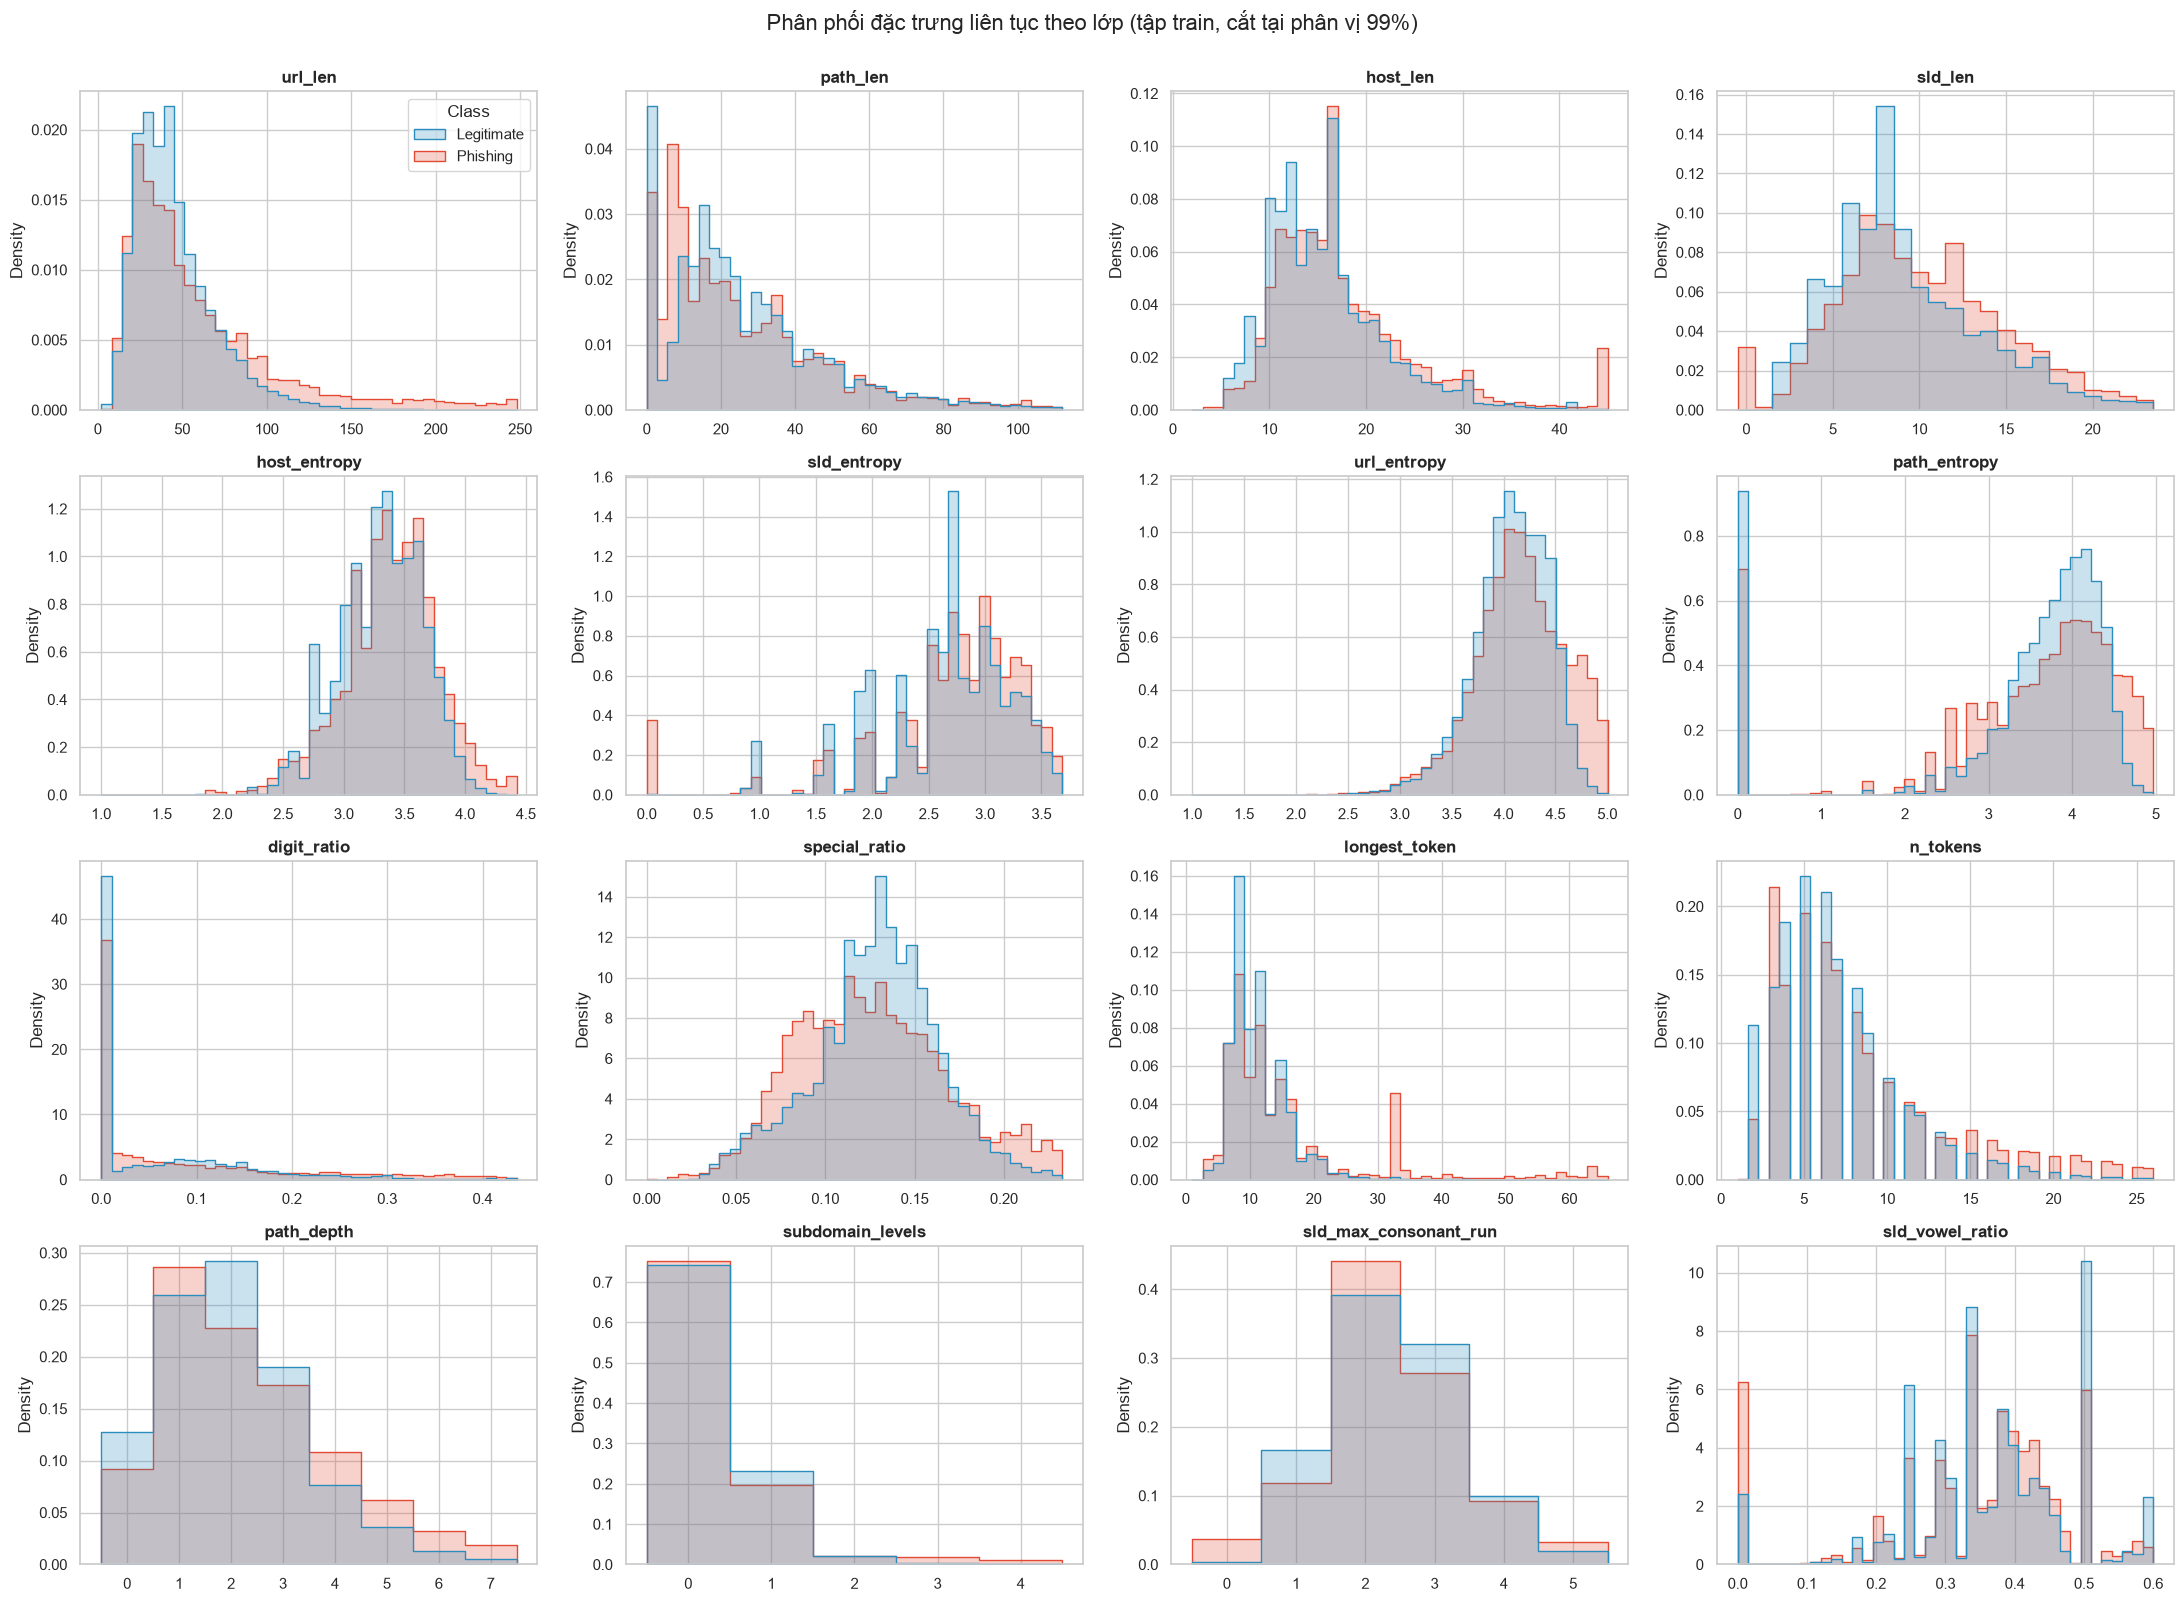

In [11]:
eda = (F.iloc[train_idx].assign(Class=np.where(y_train == 1, 'Phishing', 'Legitimate'))
         .sample(n=min(PLOT_SAMPLE, len(train_idx)), random_state=RANDOM_STATE))

CONT_FEATURES = ['url_len', 'path_len', 'host_len', 'sld_len',
                 'host_entropy', 'sld_entropy', 'url_entropy', 'path_entropy',
                 'digit_ratio', 'special_ratio', 'longest_token', 'n_tokens',
                 'path_depth', 'subdomain_levels', 'sld_max_consonant_run', 'sld_vowel_ratio']

fig, axes = plt.subplots(4, 4, figsize=(22, 16))
for i, (ax, col) in enumerate(zip(axes.ravel(), CONT_FEATURES)):
    data = eda[eda[col] <= eda[col].quantile(0.99)]
    discrete = data[col].nunique() <= 25
    sns.histplot(data=data, x=col, hue='Class', stat='density', common_norm=False, element='step',
                 discrete=discrete, bins='auto' if discrete else 40, palette=PALETTE, ax=ax, legend=(i == 0))
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('')
fig.suptitle('Phân phối đặc trưng liên tục theo lớp (tập train, cắt tại phân vị 99%)', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

Với các **đặc trưng nhị phân (cờ)**, biểu đồ cột so sánh **tỉ lệ phishing khi cờ bật** với tỉ lệ phishing chung (đường nét đứt), kèm số mẫu có cờ bật. Cờ càng nằm xa đường nét đứt thì càng có tính phân biệt.

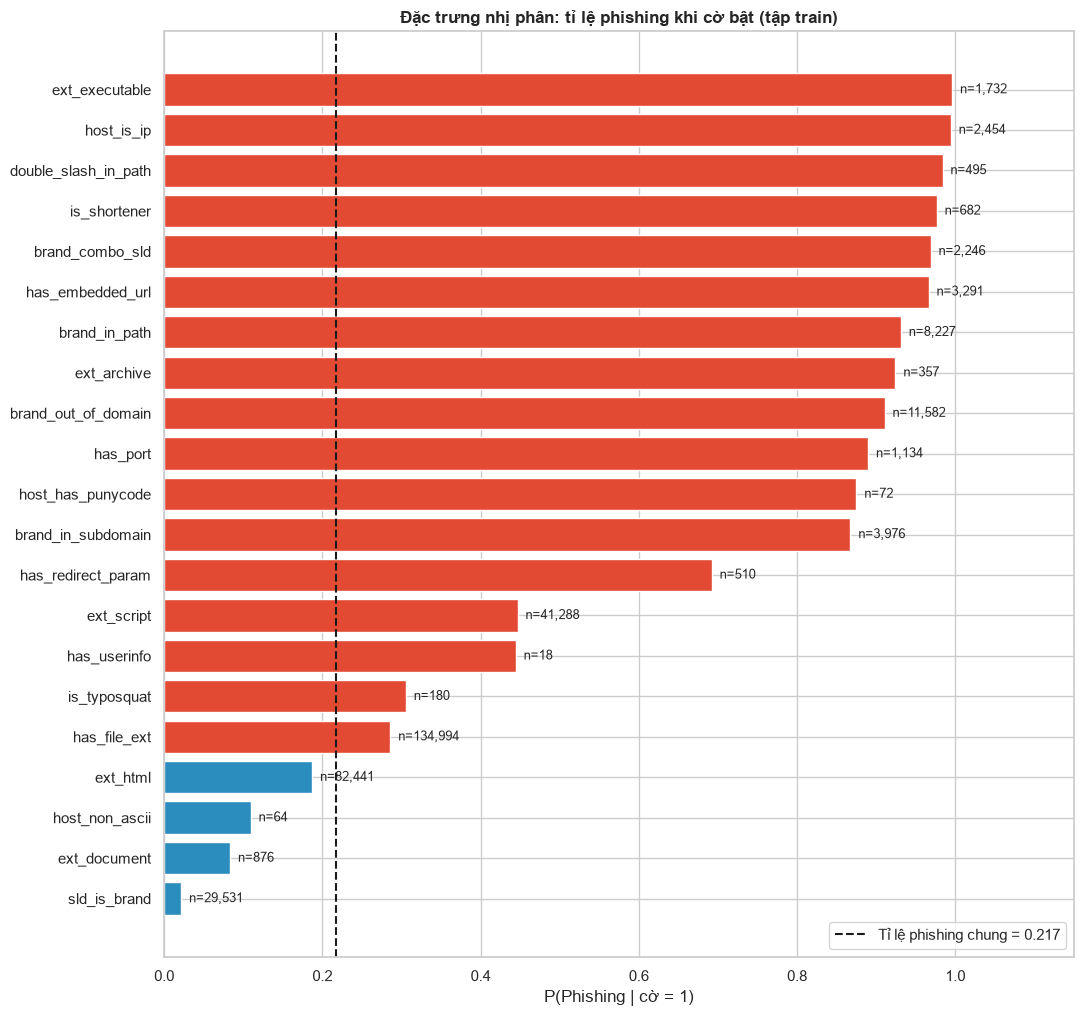

,n_bật,tỉ_lệ_bật (%),tỉ_lệ_phishing_khi_bật
sld_is_brand,29531,8.411,0.021
ext_document,876,0.250,0.083
host_non_ascii,64,0.018,0.109
ext_html,82441,23.481,0.187
has_file_ext,134994,38.450,0.286
is_typosquat,180,0.051,0.306
has_userinfo,18,0.005,0.444
ext_script,41288,11.760,0.447
has_redirect_param,510,0.145,0.692
brand_in_subdomain,3976,1.132,0.867


In [12]:
BIN_FEATURES = [c for c in NUM_COLS if set(np.unique(F[c].iloc[train_idx])) <= {0, 1}]
F_tr = F.iloc[train_idx]
flag_stats = pd.DataFrame({
    'n_bật': [int(F_tr[c].sum()) for c in BIN_FEATURES],
    'tỉ_lệ_bật (%)': [F_tr[c].mean() * 100 for c in BIN_FEATURES],
    'tỉ_lệ_phishing_khi_bật': [y_train[F_tr[c].to_numpy() == 1].mean() for c in BIN_FEATURES],
}, index=BIN_FEATURES).sort_values('tỉ_lệ_phishing_khi_bật')

fig, ax = plt.subplots(figsize=(11, 0.42 * len(flag_stats) + 1.5))
colors = ['#e34a33' if r > y_train.mean() else '#2b8cbe' for r in flag_stats['tỉ_lệ_phishing_khi_bật']]
ax.barh(flag_stats.index, flag_stats['tỉ_lệ_phishing_khi_bật'], color=colors)
ax.axvline(y_train.mean(), ls='--', c='k', label=f'Tỉ lệ phishing chung = {y_train.mean():.3f}')
for i, (rate, n) in enumerate(zip(flag_stats['tỉ_lệ_phishing_khi_bật'], flag_stats['n_bật'])):
    ax.text(rate + 0.01, i, f'n={n:,}', va='center', fontsize=9)
ax.set_xlim(0, 1.15)
ax.set_xlabel('P(Phishing | cờ = 1)')
ax.set_title('Đặc trưng nhị phân: tỉ lệ phishing khi cờ bật (tập train)', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()
display(flag_stats.round(3))

## 9. Ma trận tương quan (Correlation Heatmap)

Notebook dùng **tương quan Spearman**, phù hợp hơn Pearson với các đặc trưng đếm bị lệch mạnh. Mục đích: (1) phát hiện các đặc trưng **đa cộng tuyến**. Chúng không gây hại cho mô hình cây nhưng làm importance bị chia nhỏ giữa các cột và ảnh hưởng tới mô hình tuyến tính. (2) Xem mức tương quan đơn biến của từng đặc trưng với nhãn.

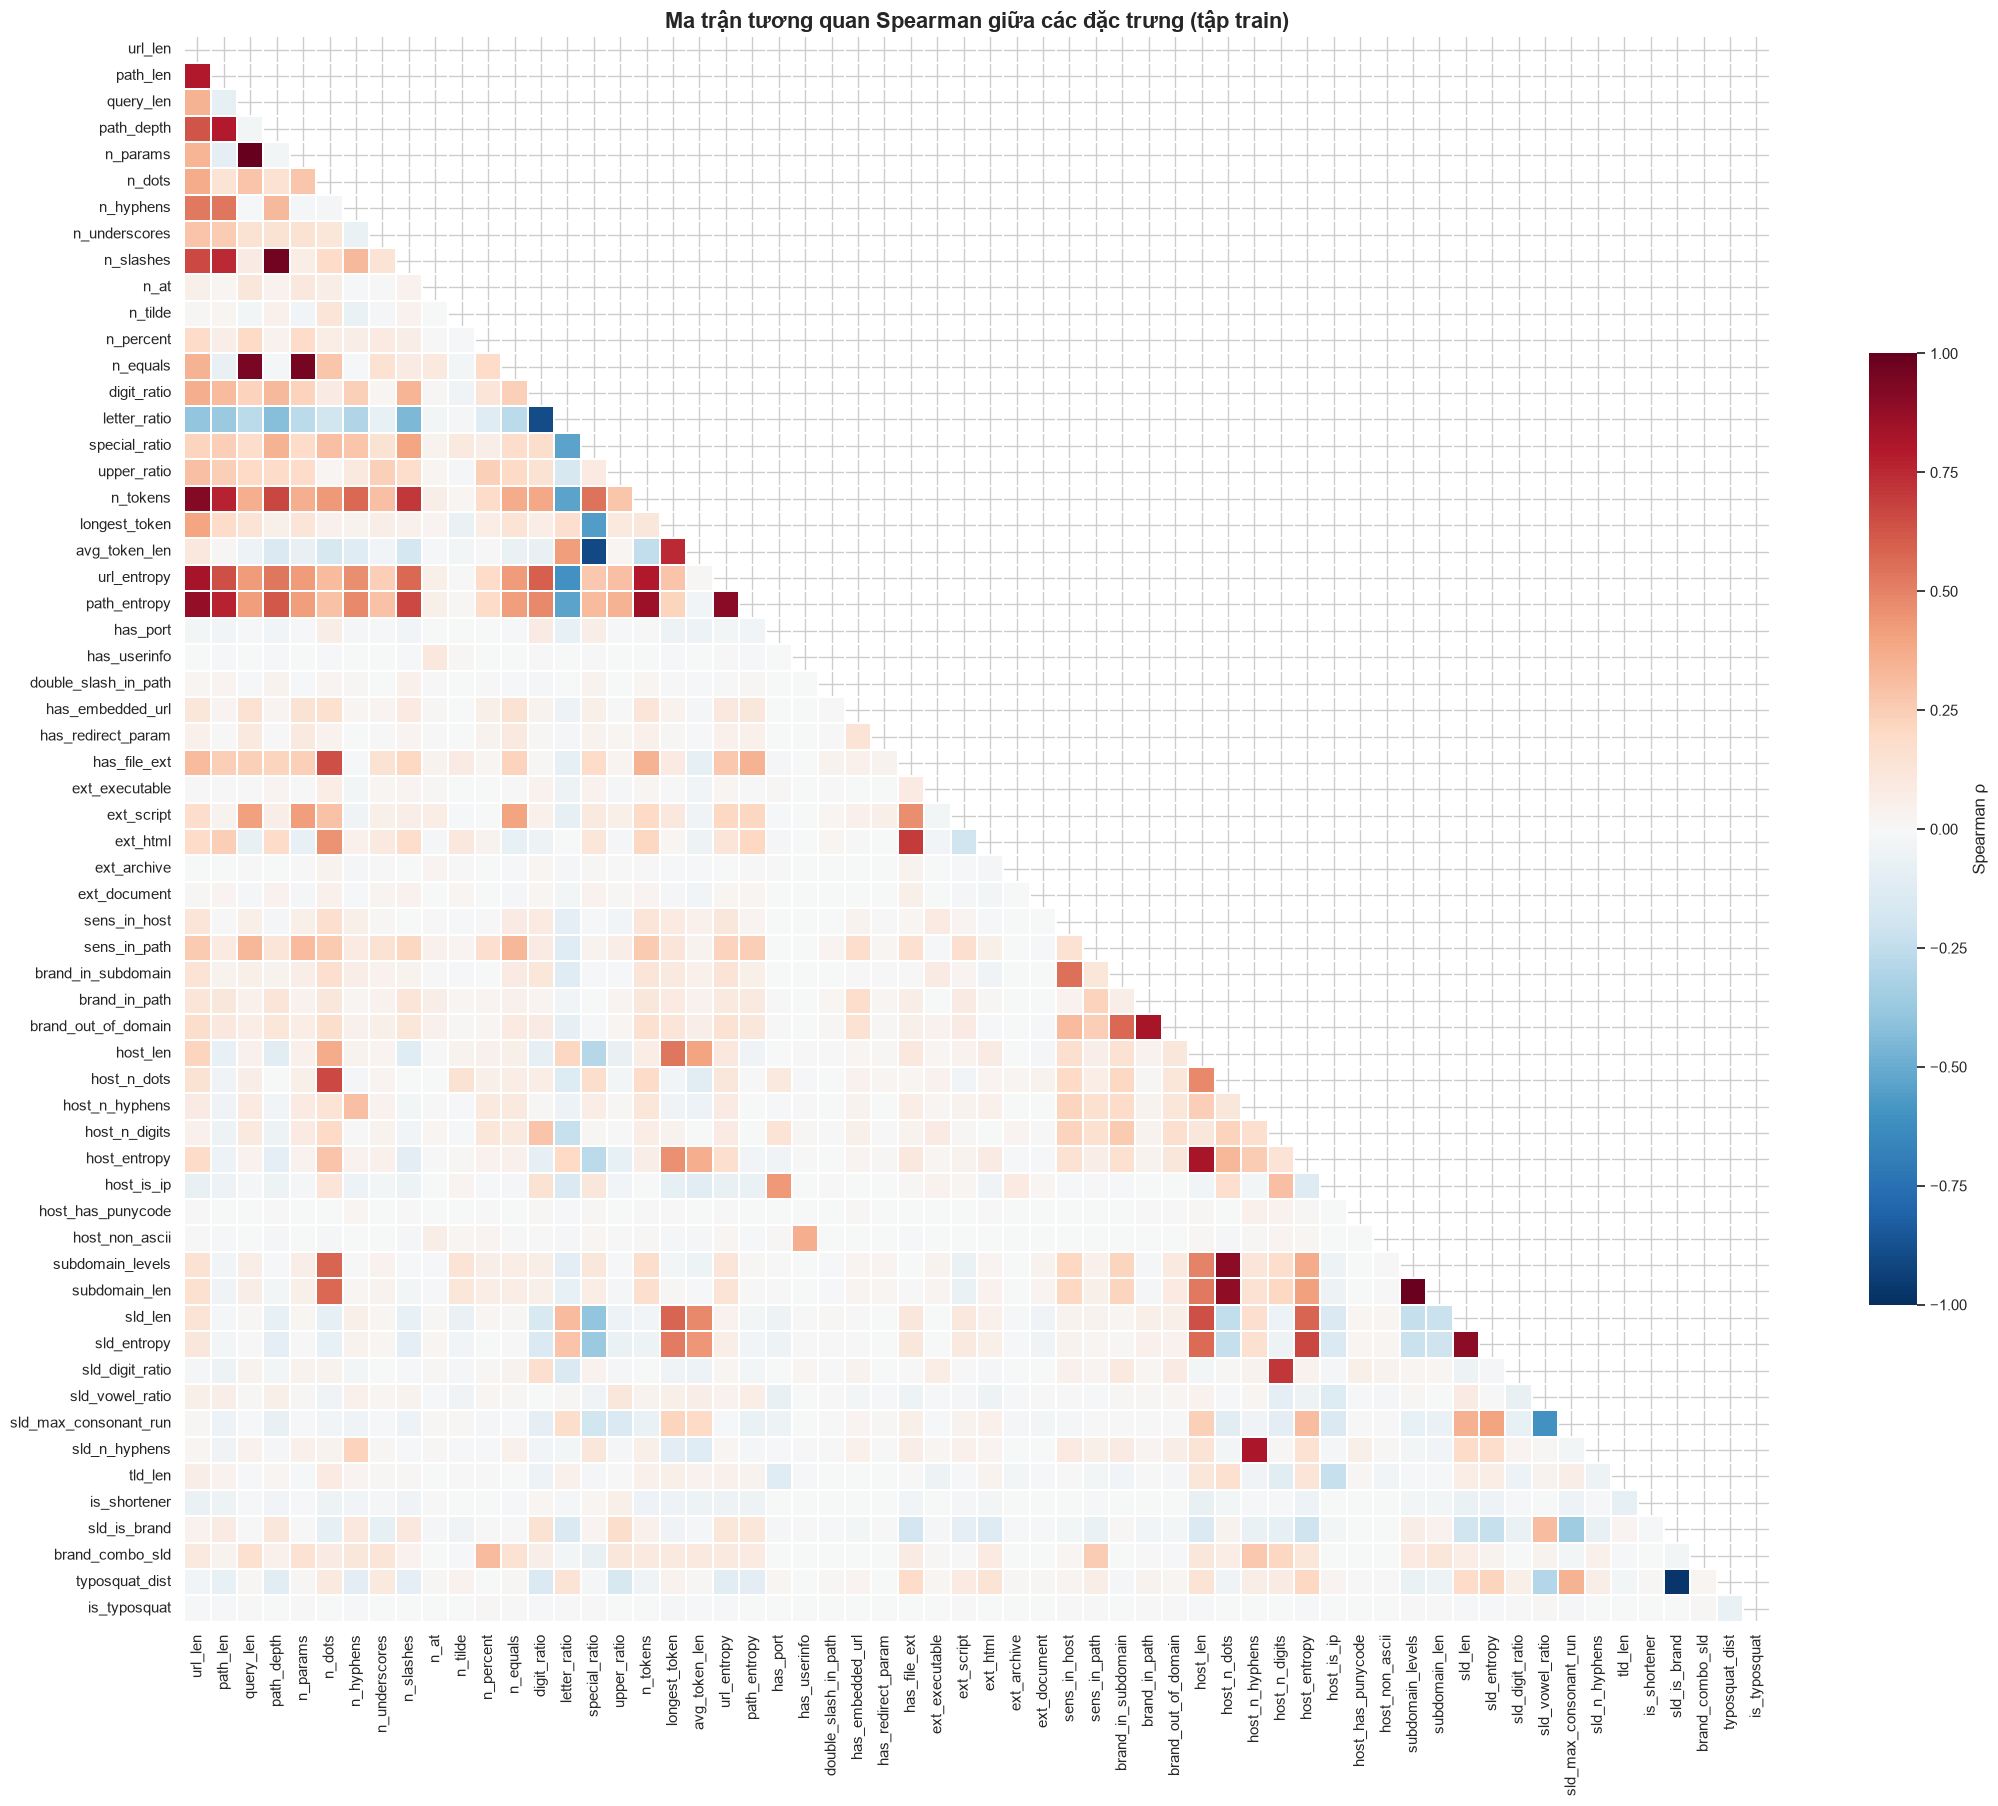

9 cặp đặc trưng có |ρ| ≥ 0.9:


,feature_1,feature_2,rho
0,n_params,query_len,0.998
1,subdomain_len,subdomain_levels,0.988
2,typosquat_dist,sld_is_brand,-0.969
3,n_slashes,path_depth,0.964
4,n_equals,n_params,0.955
5,n_equals,query_len,0.951
6,n_tokens,url_len,0.918
7,avg_token_len,special_ratio,-0.905
8,path_entropy,url_entropy,0.901


In [13]:
corr_cols = NUM_COLS
corr = eda[corr_cols].corr(method='spearman')

mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(22, 18))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.3, cbar_kws={'shrink': 0.6, 'label': 'Spearman ρ'}, ax=ax)
ax.set_title('Ma trận tương quan Spearman giữa các đặc trưng (tập train)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Các cặp tương quan rất cao
pairs = (corr.where(~mask).stack().rename('rho').reset_index()
             .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2'}))
high = pairs[pairs['rho'].abs() >= 0.9].sort_values('rho', key=np.abs, ascending=False)
print(f'{len(high)} cặp đặc trưng có |ρ| ≥ 0.9:')
display(high.round(3).reset_index(drop=True))

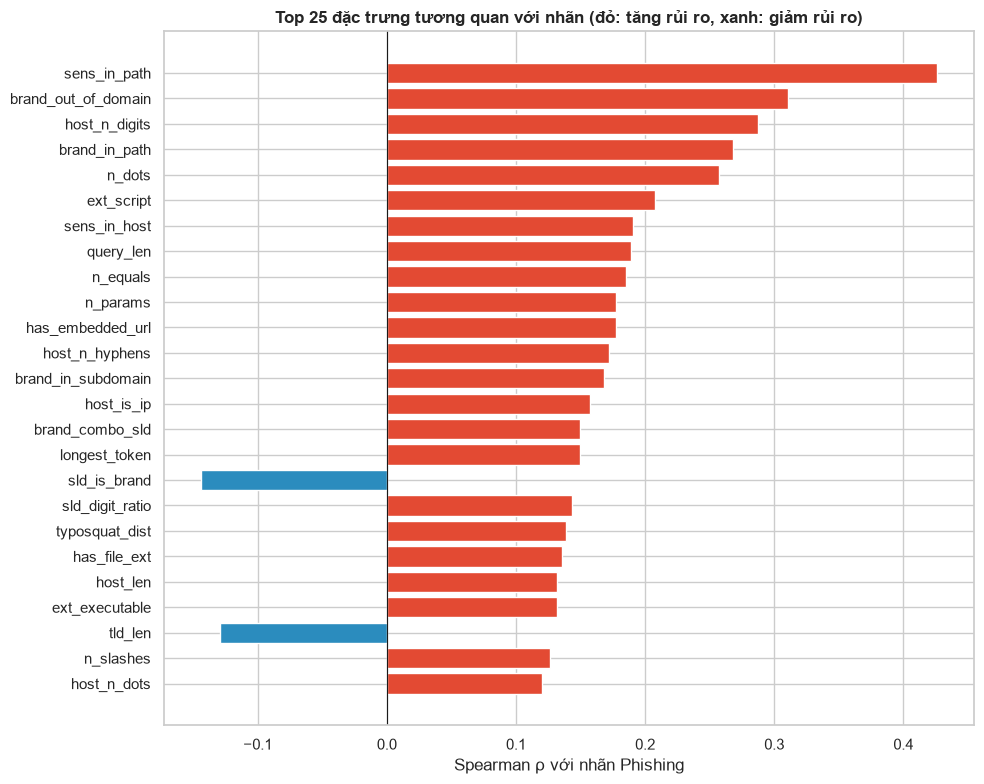

In [14]:
# Tương quan đơn biến (Spearman) giữa từng đặc trưng và nhãn: top 25 theo |ρ|
label_corr = eda[corr_cols].corrwith((eda['Class'] == 'Phishing').astype(int), method='spearman').dropna()
top = label_corr.reindex(label_corr.abs().sort_values(ascending=False).index).head(25)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top.index[::-1], top.values[::-1], color=np.where(top.values[::-1] > 0, '#e34a33', '#2b8cbe'))
ax.axvline(0, c='k', lw=0.8)
ax.set_xlabel('Spearman ρ với nhãn Phishing')
ax.set_title('Top 25 đặc trưng tương quan với nhãn (đỏ: tăng rủi ro, xanh: giảm rủi ro)', fontweight='bold')
plt.tight_layout()
plt.show()

## 10. Tiện ích đánh giá

Các hàm dùng chung cho **mọi** mô hình, để đảm bảo giao thức đánh giá đồng nhất:

- **Chọn ngưỡng trên Validation:** ngưỡng tối đa hóa F1 trên tập val, sau đó áp nguyên ngưỡng đó lên test. Ngưỡng **không** được chọn trên test, nên tránh được selection bias.
- **Chỉ số:** Accuracy, Precision, Recall, F1, ROC-AUC (yêu cầu bắt buộc), cùng PR-AUC, **Recall @ FPR ≤ 1%** (chỉ số vận hành của hệ thống chặn URL), F1@0.5, FPR/FNR và Brier score.
- **Biểu đồ cho từng mô hình:** ROC Curve, Precision–Recall Curve và Confusion Matrix.

In [15]:
RESULTS = {}   # tên mô hình → dict metrics trên TEST
PROBAS = {}    # tên mô hình → (proba_val, proba_test)


def find_best_f1_threshold(y_true, proba) -> float:
    prec, rec, thr = precision_recall_curve(y_true, proba)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.nanargmax(f1[:-1])])


def recall_at_fpr(y_true, proba, max_fpr=0.01) -> float:
    fpr, tpr, _ = roc_curve(y_true, proba)
    return float(np.interp(max_fpr, fpr, tpr))


def compute_metrics(y_true, proba, threshold) -> dict:
    y_pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, proba),
        'PR-AUC': average_precision_score(y_true, proba),
        'Recall@FPR≤1%': recall_at_fpr(y_true, proba, 0.01),
        'F1@0.5': f1_score(y_true, (proba >= 0.5).astype(int)),
        'FPR': fp / (fp + tn), 'FNR': fn / (fn + tp),
        'Brier': brier_score_loss(y_true, proba),
        'Threshold': threshold, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }


def plot_evaluation(name, y_true, proba, threshold):
    """ROC + Precision-Recall + Confusion Matrix cho một mô hình."""
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
    fpr, tpr, _ = roc_curve(y_true, proba)
    axes[0].plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc_score(y_true, proba):.4f}')
    axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
    axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC Curve')
    axes[0].legend(loc='lower right')

    prec, rec, _ = precision_recall_curve(y_true, proba)
    axes[1].plot(rec, prec, lw=2, c='#e34a33', label=f'AP = {average_precision_score(y_true, proba):.4f}')
    axes[1].axhline(y_true.mean(), ls='--', c='k', lw=1, label=f'Ngẫu nhiên = {y_true.mean():.3f}')
    y_pred = (proba >= threshold).astype(int)
    axes[1].scatter(recall_score(y_true, y_pred), precision_score(y_true, y_pred), s=80, c='k', zorder=5,
                    label=f'Ngưỡng {threshold:.3f}')
    axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall Curve', ylim=(0, 1.02))
    axes[1].legend(loc='lower left')

    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=LABELS, cmap='Blues',
                                            values_format=',', ax=axes[2], colorbar=False)
    axes[2].set_title(f'Confusion Matrix (ngưỡng = {threshold:.3f})')
    axes[2].grid(False)
    fig.suptitle(f'{name}: đánh giá trên tập TEST', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


def evaluate_model(name, p_val, p_test, group='Mô hình mới', fixed_threshold=None) -> None:
    """Chọn ngưỡng trên val (hoặc dùng ngưỡng cố định), tính metrics trên test, vẽ biểu đồ."""
    thr = fixed_threshold if fixed_threshold is not None else find_best_f1_threshold(y_val, p_val)
    m = compute_metrics(y_test, p_test, thr)
    m['Group'] = group
    RESULTS[name], PROBAS[name] = m, (p_val, p_test)
    plot_evaluation(name, y_test, p_test, thr)
    show = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC', 'Recall@FPR≤1%',
            'F1@0.5', 'FPR', 'FNR', 'Threshold']
    display(pd.DataFrame({k: [m[k]] for k in show}, index=[name]).round(4))

## 11. Baseline: tái lập mô hình cũ trên cùng split mới

Để so sánh **công bằng** (cùng dữ liệu, cùng tập test, cùng giao thức), ta tái lập chính xác pipeline cũ:
- **20 đặc trưng cũ** từ `src/features/` (tính trên URL **thô**, chưa chuẩn hóa, đúng như notebook 04/05).
- **Random Forest** (`n_estimators=100`) và **XGBoost** với bộ tham số tốt nhất của notebook 05.
- Ngưỡng **0.5** cố định, như notebook cũ.

> Các số liệu gốc mà notebook 05 báo cáo (chia ngẫu nhiên, có rò rỉ domain) được đưa vào bảng so sánh ở §17 để tham chiếu.

In [16]:
# Thứ tự cột y hệt X_train của notebook 05
BASELINE_COLS = ['get_url_length', 'get_hostname_length', 'count_dots', 'count_hyphens', 'count_at_symbol',
                 'count_slashes', 'count_question_mark', 'count_equals', 'count_and_symbol', 'get_path_length',
                 'count_digits_in_url', 'count_letters_in_url', 'count_digits_in_hostname', 'has_https',
                 'has_suspicious_tld', 'count_sensitive_words', 'has_ip_address_in_hostname',
                 'get_subdomain_count', 'get_domain_age_days', 'get_domain_lifespan_days']
BASELINE_FUNCS = {c: getattr(lexical_features, c, None) or getattr(host_features, c) for c in BASELINE_COLS}


def baseline_feature_frame(raw_urls) -> pd.DataFrame:
    raw_urls = list(raw_urls)
    return pd.DataFrame({c: [f(u) for u in raw_urls] for c, f in BASELINE_FUNCS.items()}).astype(float)


t0 = time.time()
B = baseline_feature_frame(df['url'])
B_train, B_val, B_test = B.iloc[train_idx], B.iloc[val_idx], B.iloc[test_idx]
print(f'Trích xuất 20 đặc trưng cũ trong {time.time() - t0:.1f}s → {B.shape}')

Trích xuất 20 đặc trưng cũ trong 43.5s → (501550, 20)


Baseline RF train: 18.7s


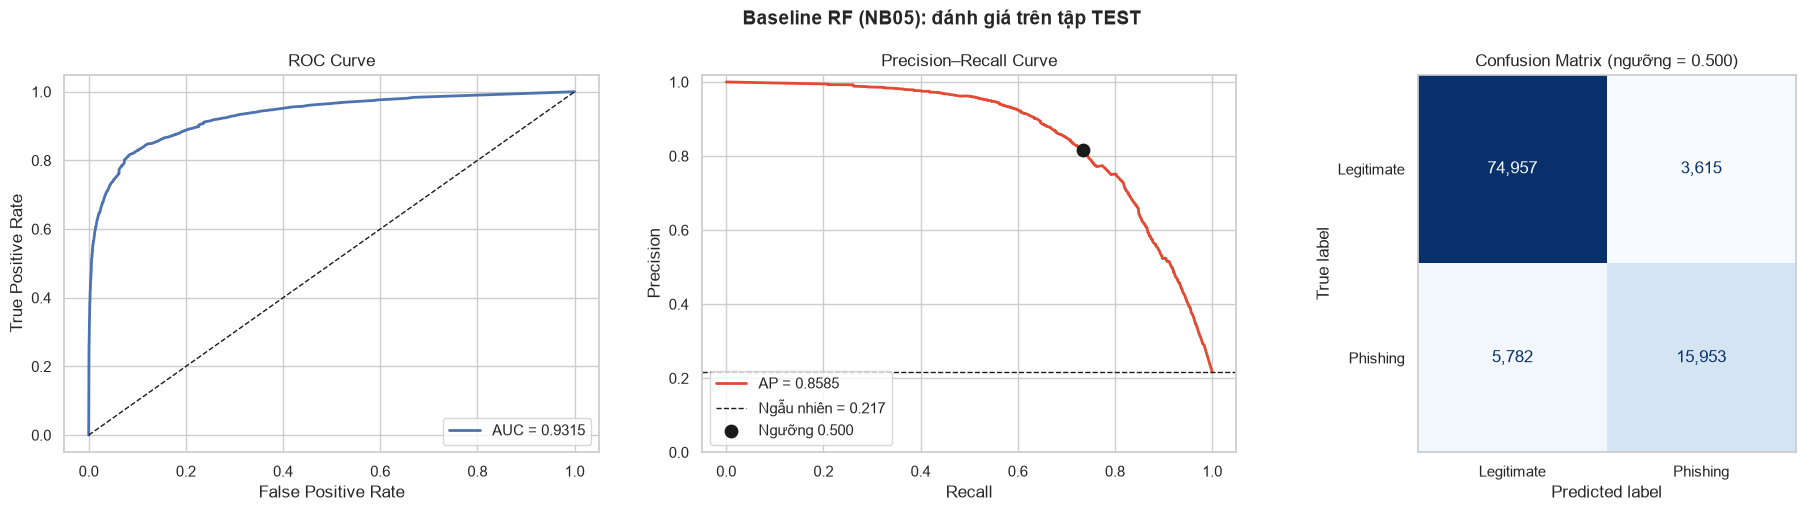

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Recall@FPR≤1%,F1@0.5,FPR,FNR,Threshold
Baseline RF (NB05),0.9063,0.8153,0.734,0.7725,0.9315,0.8585,0.563,0.7725,0.046,0.266,0.5


In [17]:
NAME_BASE_RF, NAME_BASE_XGB = 'Baseline RF (NB05)', 'Baseline XGBoost tuned (NB05)'

t0 = time.time()
base_rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1).fit(B_train, y_train)
print(f'Baseline RF train: {time.time() - t0:.1f}s')
evaluate_model(NAME_BASE_RF, base_rf.predict_proba(B_val)[:, 1], base_rf.predict_proba(B_test)[:, 1],
               group='Baseline (tái lập)', fixed_threshold=0.5)

Baseline XGBoost train: 10.5s


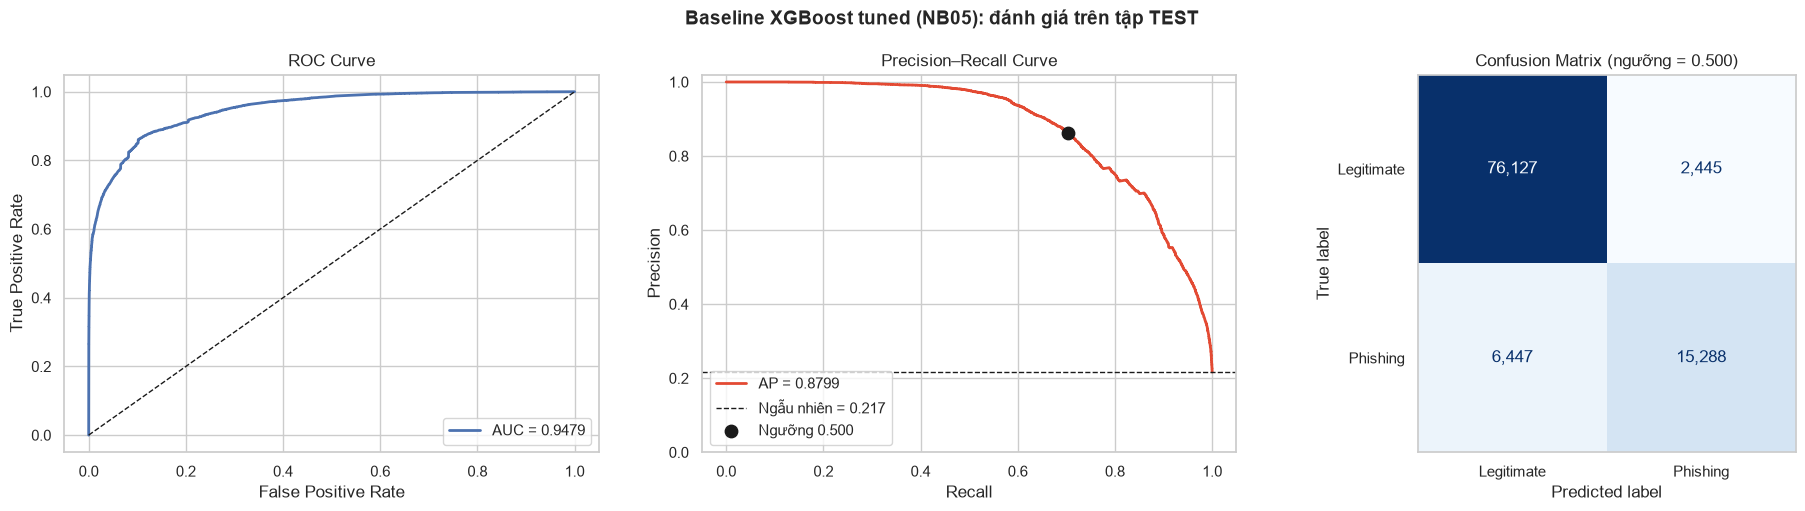

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Recall@FPR≤1%,F1@0.5,FPR,FNR,Threshold
Baseline XGBoost tuned (NB05),0.9114,0.8621,0.7034,0.7747,0.9479,0.8799,0.5904,0.7747,0.0311,0.2966,0.5


In [18]:
t0 = time.time()
base_xgb = XGBClassifier(subsample=0.9, n_estimators=300, max_depth=10, learning_rate=0.05,
                         colsample_bytree=0.8, random_state=RANDOM_STATE, eval_metric='logloss',
                         n_jobs=-1).fit(B_train, y_train)
print(f'Baseline XGBoost train: {time.time() - t0:.1f}s')
evaluate_model(NAME_BASE_XGB, base_xgb.predict_proba(B_val)[:, 1], base_xgb.predict_proba(B_test)[:, 1],
               group='Baseline (tái lập)', fixed_threshold=0.5)

## 12. Mô hình 1: Logistic Regression trên TF-IDF (char n-gram và token)

Biểu diễn **TF-IDF char n-gram (3–5)** giữ lại thông tin chuỗi mà 20 đặc trưng đếm cũ làm mất (ví dụ `aypa`, `.php?`, `webscr`, `-secure`). Kết hợp thêm **TF-IDF token** (tách theo ký tự không phải chữ/số). Bộ vectorizer **chỉ fit trên train**.

- **Mô hình:** Logistic Regression (`liblinear`) với `class_weight='balanced'` để xử lý mất cân bằng lớp.
- **Siêu tham số `C`:** chọn trên validation theo PR-AUC.

In [19]:
char_vec = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=5, max_features=300_000,
                           sublinear_tf=True, dtype=np.float32)
word_vec = TfidfVectorizer(token_pattern=r'[a-z0-9]{2,}', min_df=3, sublinear_tf=True, dtype=np.float32)


def vectorize(texts):
    """URL đã chuẩn hóa → ma trận TF-IDF thưa (char ⊕ token)."""
    return sparse.hstack([char_vec.transform(texts), word_vec.transform(texts)]).tocsr()


texts = df['url_norm']
t0 = time.time()
T_train = sparse.hstack([char_vec.fit_transform(texts.iloc[train_idx]),
                         word_vec.fit_transform(texts.iloc[train_idx])]).tocsr()
T_val, T_test = vectorize(texts.iloc[val_idx]), vectorize(texts.iloc[test_idx])
print(f'TF-IDF xong trong {time.time() - t0:.1f}s')
print(f'Train: {T_train.shape}, nnz = {T_train.nnz:,} | '
      f'vocab char = {len(char_vec.vocabulary_):,}, token = {len(word_vec.vocabulary_):,}')

TF-IDF xong trong 100.7s
Train: (351090, 351710), nnz = 44,287,048 | vocab char = 300,000, token = 51,710


In [20]:
# Chọn C trên validation
lr_search = {}
for C in [0.5, 2.0, 8.0]:
    t0 = time.time()
    m = LogisticRegression(C=C, solver='liblinear', class_weight='balanced', max_iter=300).fit(T_train, y_train)
    ap = average_precision_score(y_val, m.predict_proba(T_val)[:, 1])
    lr_search[C] = (ap, m)
    print(f'C = {C:<4} | val PR-AUC = {ap:.4f} | {time.time() - t0:.1f}s')

BEST_C = max(lr_search, key=lambda c: lr_search[c][0])
lr_tfidf = lr_search[BEST_C][1]
print(f'→ Chọn C = {BEST_C}')

C = 0.5  | val PR-AUC = 0.9717 | 27.0s


C = 2.0  | val PR-AUC = 0.9766 | 38.5s


C = 8.0  | val PR-AUC = 0.9773 | 65.8s
→ Chọn C = 8.0


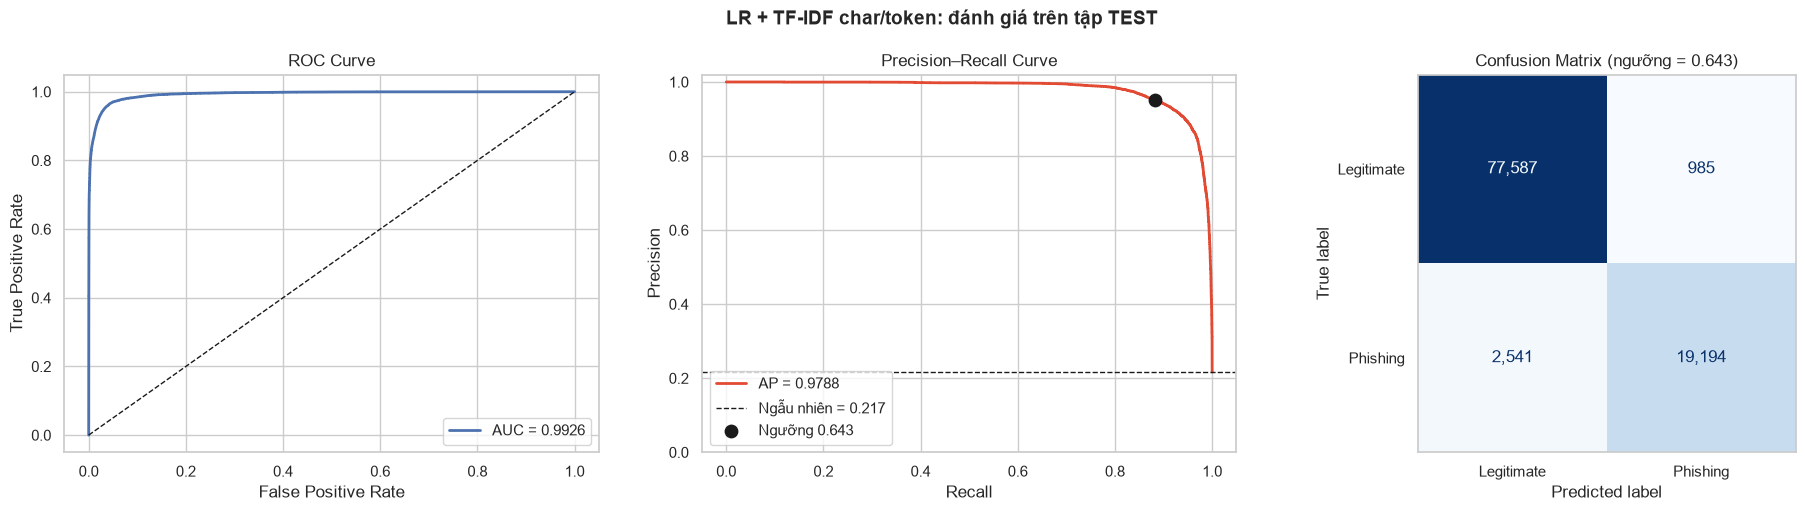

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Recall@FPR≤1%,F1@0.5,FPR,FNR,Threshold
LR + TF-IDF char/token,0.9648,0.9512,0.8831,0.9159,0.9926,0.9788,0.8648,0.9229,0.0125,0.1169,0.6429


In [21]:
NAME_LR = 'LR + TF-IDF char/token'
p_val_lr, p_test_lr = lr_tfidf.predict_proba(T_val)[:, 1], lr_tfidf.predict_proba(T_test)[:, 1]
evaluate_model(NAME_LR, p_val_lr, p_test_lr)

**Khả năng giải thích:** hệ số của Logistic Regression cho biết n-gram nào đẩy URL về phía phishing (dương) hoặc hợp lệ (âm).

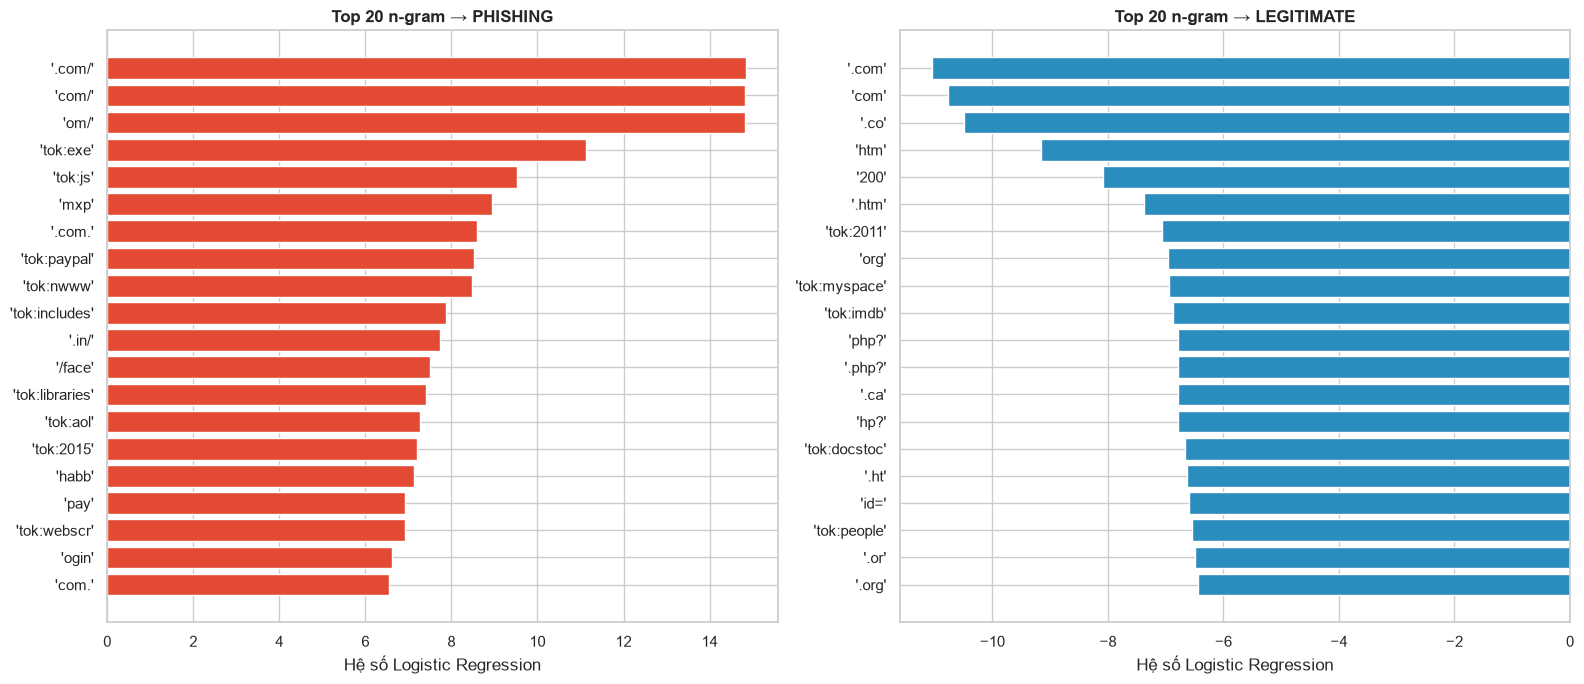

In [22]:
vocab = np.concatenate([char_vec.get_feature_names_out(),
                        np.char.add('tok:', word_vec.get_feature_names_out().astype(str))])
coef = lr_tfidf.coef_.ravel()
order = np.argsort(coef)
top_neg, top_pos = order[:20], order[-20:]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].barh([repr(vocab[i]) for i in top_pos], coef[top_pos], color='#e34a33')
axes[0].set_title('Top 20 n-gram → PHISHING', fontweight='bold')
axes[1].barh([repr(vocab[i]) for i in top_neg[::-1]], coef[top_neg[::-1]], color='#2b8cbe')
axes[1].set_title('Top 20 n-gram → LEGITIMATE', fontweight='bold')
for ax in axes:
    ax.set_xlabel('Hệ số Logistic Regression')
plt.tight_layout()
plt.show()

## 13. Mô hình 2: Histogram Gradient Boosting trên đặc trưng thủ công

`HistGradientBoostingClassifier` của scikit-learn dùng **cùng thuật toán với LightGBM** (rời rạc hóa đặc trưng thành histogram, mọc cây theo lá), nên không cần cài thêm thư viện.

- **TLD** được mã hóa bằng **Target Encoding** (`TargetEncoder`). Trên tập train, bộ mã hóa dùng *cross-fitting* nội bộ, nên giá trị mã hóa của một mẫu không chứa chính nhãn của nó (tránh rò rỉ nhãn).
- **Mất cân bằng lớp:** xử lý bằng `class_weight='balanced'`.
- **Early stopping:** bật sẵn trong mô hình.

In [23]:
te_tld = TargetEncoder(target_type='binary', cv=5, shuffle=True, random_state=RANDOM_STATE)


def assemble_hand_matrix(F_part: pd.DataFrame, tld_encoded) -> pd.DataFrame:
    """Ghép đặc trưng số + TLD đã target-encode → ma trận cho mô hình cây."""
    X = F_part[NUM_COLS].astype(np.float32).reset_index(drop=True)
    X['tld_target_enc'] = np.asarray(tld_encoded, dtype=np.float32).ravel()
    return X


X_train = assemble_hand_matrix(F.iloc[train_idx],
                               te_tld.fit_transform(F.iloc[train_idx][['tld']].astype(object), y_train))
X_val = assemble_hand_matrix(F.iloc[val_idx], te_tld.transform(F.iloc[val_idx][['tld']].astype(object)))
X_test = assemble_hand_matrix(F.iloc[test_idx], te_tld.transform(F.iloc[test_idx][['tld']].astype(object)))
HAND_COLS = list(X_train.columns)
print(f'Ma trận đặc trưng thủ công: train {X_train.shape}, val {X_val.shape}, test {X_test.shape}')

tld_risk = (pd.DataFrame({'tld': F.iloc[train_idx]['tld'].to_numpy(), 'y': y_train})
              .groupby('tld')['y'].agg(n='size', phishing_rate='mean').query('n >= 200')
              .sort_values('phishing_rate', ascending=False))
print('TLD rủi ro cao nhất (≥ 200 URL trong train):')
display(tld_risk.head(10).round(3))

Ma trận đặc trưng thủ công: train (351090, 61), val (50153, 61), test (100307, 61)
TLD rủi ro cao nhất (≥ 200 URL trong train):


,n,phishing_rate
tld,,
xyz,224,1.000
top,279,1.000
<ip>,2454,0.994
mx,698,0.994
cn,716,0.992
asia,594,0.990
cl,657,0.982
com.br,2135,0.978
com.mx,207,0.976


HGB train: 104.4s | số vòng boosting: 853


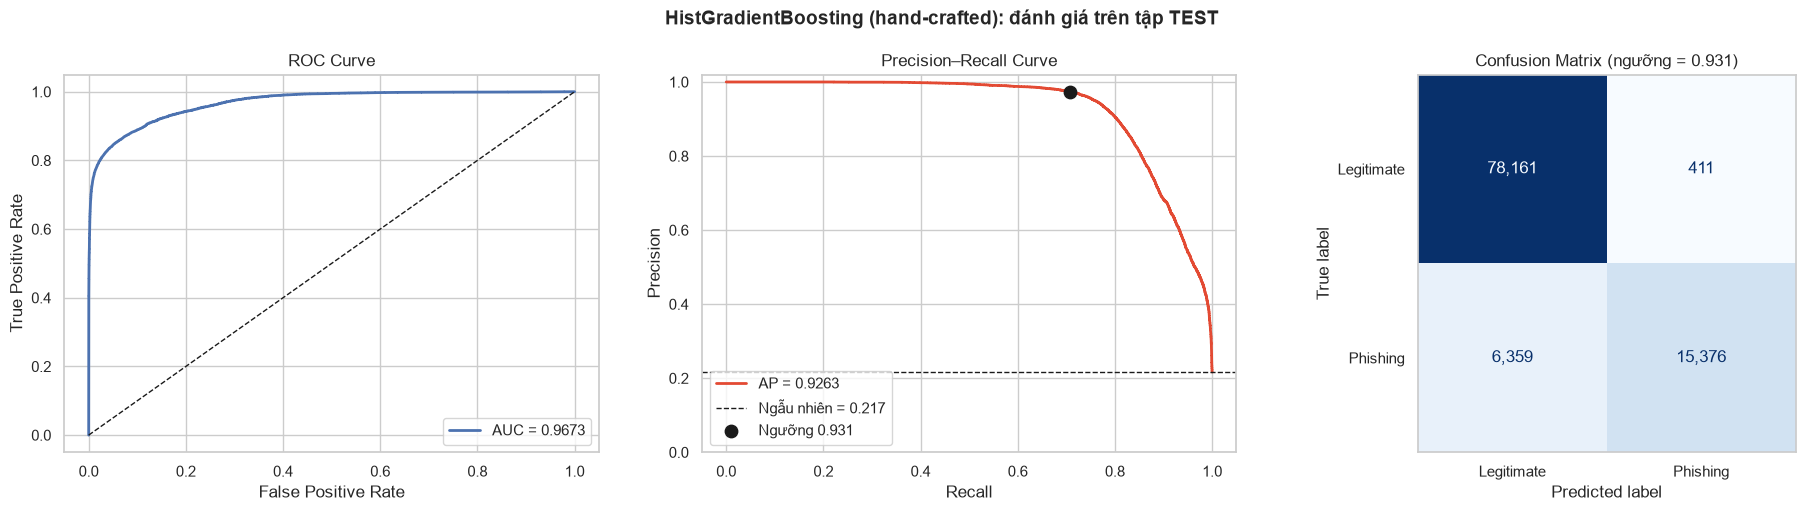

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Recall@FPR≤1%,F1@0.5,FPR,FNR,Threshold
HistGradientBoosting (hand-crafted),0.9325,0.974,0.7074,0.8196,0.9673,0.9263,0.7522,0.8186,0.0052,0.2926,0.9313


In [24]:
NAME_HGB = 'HistGradientBoosting (hand-crafted)'
t0 = time.time()
hgb = HistGradientBoostingClassifier(learning_rate=0.08, max_iter=1000, max_leaf_nodes=63, min_samples_leaf=40,
                                     l2_regularization=1.0, class_weight='balanced', early_stopping=True,
                                     validation_fraction=0.1, n_iter_no_change=30, random_state=RANDOM_STATE)
hgb.fit(X_train, y_train)
print(f'HGB train: {time.time() - t0:.1f}s | số vòng boosting: {hgb.n_iter_}')
evaluate_model(NAME_HGB, hgb.predict_proba(X_val)[:, 1], hgb.predict_proba(X_test)[:, 1])

**Feature Importance (Permutation Importance):** HistGradientBoosting không có sẵn `feature_importances_`. Ta đo mức **giảm PR-AUC trên tập validation** khi xáo trộn ngẫu nhiên từng đặc trưng. Cách đo này đáng tin hơn MDI vì không thiên vị các đặc trưng có nhiều giá trị.

Permutation importance: 94.9s


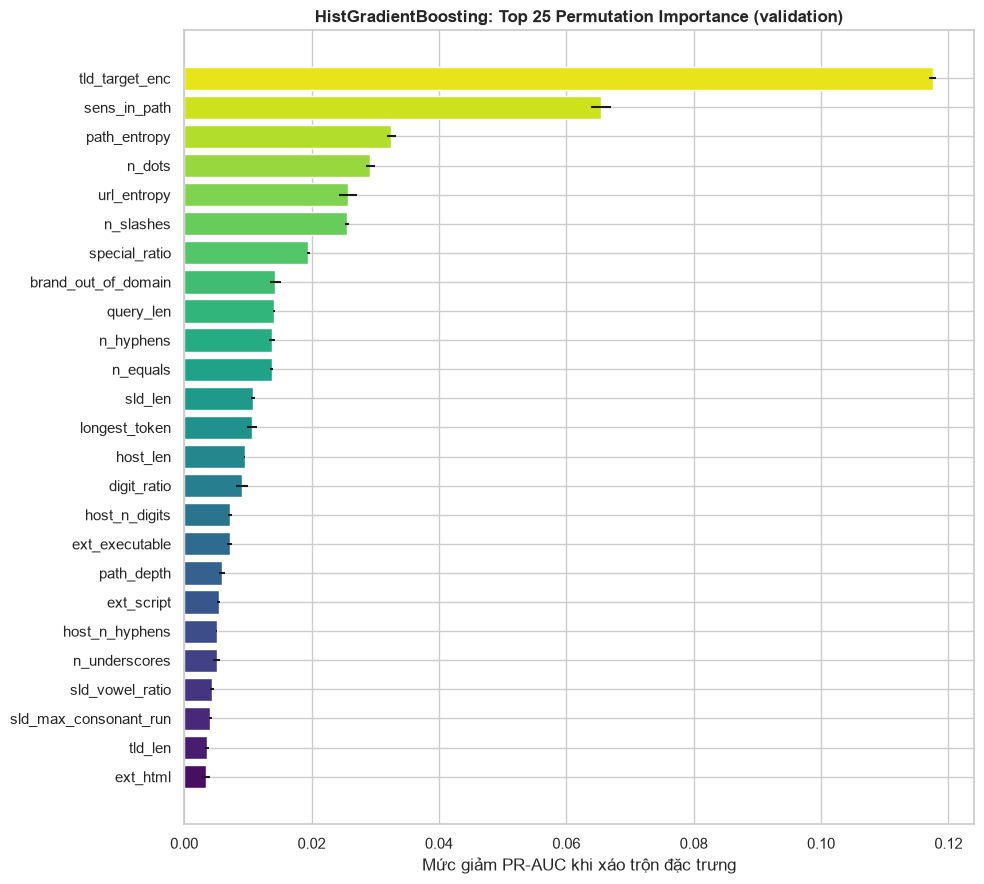

In [25]:
t0 = time.time()
sample = np.random.RandomState(RANDOM_STATE).choice(len(X_val), size=min(30_000, len(X_val)), replace=False)
perm = permutation_importance(hgb, X_val.iloc[sample], y_val[sample], scoring='average_precision',
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std},
                        index=HAND_COLS).sort_values('mean', ascending=False)
print(f'Permutation importance: {time.time() - t0:.1f}s')

top = perm_imp.head(25)[::-1]
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top.index, top['mean'], xerr=top['std'], color=sns.color_palette('viridis', len(top)))
ax.set_xlabel('Mức giảm PR-AUC khi xáo trộn đặc trưng')
ax.set_title('HistGradientBoosting: Top 25 Permutation Importance (validation)', fontweight='bold')
plt.tight_layout()
plt.show()

## 14. Mô hình 3: XGBoost và tối ưu siêu tham số bằng Optuna

So với `RandomizedSearchCV` (15 cấu hình, tối ưu F1) của notebook 05, ở đây ta dùng:
- **Optuna TPE** (tối ưu Bayesian) với không gian rộng hơn, thêm `min_child_weight`, `gamma`, `reg_alpha`, `reg_lambda`.
- **Early stopping** trên validation, `n_estimators` lên tới 2000 (không còn bị chặn ở 300).
- **Tối ưu theo PR-AUC**, chỉ số không phụ thuộc ngưỡng. Ngưỡng được chọn riêng sau đó.
- **`scale_pos_weight` = #neg / #pos** để xử lý mất cân bằng lớp.

In [26]:
SPW = float((y_train == 0).sum() / (y_train == 1).sum())
print(f'scale_pos_weight = {SPW:.3f}')


def make_xgb(params: dict, n_estimators: int = 2000) -> XGBClassifier:
    return XGBClassifier(n_estimators=n_estimators, tree_method='hist', eval_metric='aucpr',
                         early_stopping_rounds=50, scale_pos_weight=SPW, random_state=RANDOM_STATE,
                         n_jobs=-1, **params)


def objective(trial: optuna.Trial) -> float:
    params = {
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.3, log=True),
        'max_depth': trial.suggest_int('max_depth', 4, 12),
        'min_child_weight': trial.suggest_float('min_child_weight', 1.0, 20.0, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-2, 20.0, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 5.0, log=True),
    }
    model = make_xgb(params).fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    trial.set_user_attr('best_iteration', int(model.best_iteration))
    return average_precision_score(y_val, model.predict_proba(X_val)[:, 1])


t0 = time.time()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=N_OPTUNA_TRIALS, timeout=OPTUNA_TIMEOUT)
print(f'Optuna: {len(study.trials)} trials trong {(time.time() - t0) / 60:.1f} phút')
print(f'Best val PR-AUC = {study.best_value:.4f} | best_iteration = {study.best_trial.user_attrs["best_iteration"]}')
BEST_XGB_PARAMS = study.best_params
display(pd.Series(BEST_XGB_PARAMS).to_frame('giá trị tốt nhất'))

scale_pos_weight = 3.615


Optuna: 20 trials trong 1.6 phút
Best val PR-AUC = 0.9308 | best_iteration = 73


,giá trị tốt nhất
learning_rate,0.094469
max_depth,11.000000
min_child_weight,2.180394
subsample,0.814691
colsample_bytree,0.779460
gamma,0.125140
reg_lambda,1.260069
reg_alpha,0.045051


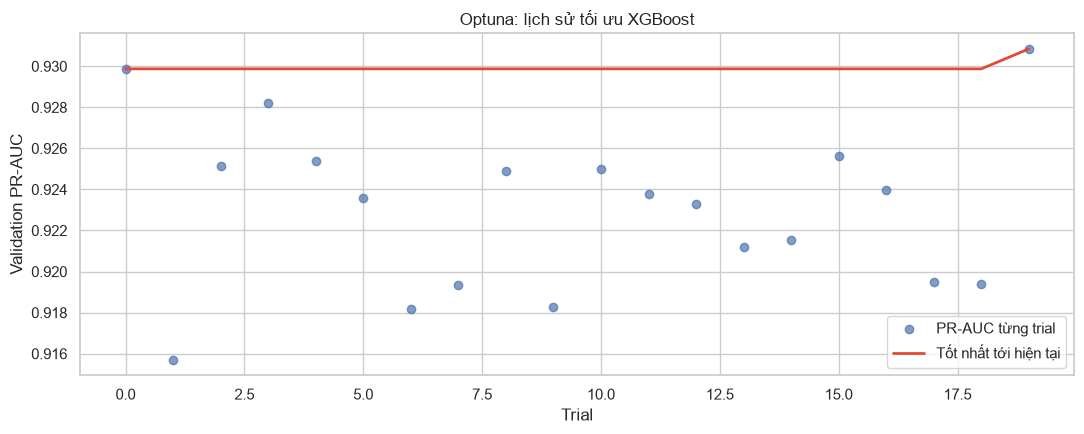

In [27]:
# Lịch sử tối ưu hóa
values = np.array([t.value for t in study.trials])
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.scatter(range(len(values)), values, alpha=0.7, label='PR-AUC từng trial')
ax.plot(np.maximum.accumulate(values), c='#e34a33', lw=2, label='Tốt nhất tới hiện tại')
ax.set(xlabel='Trial', ylabel='Validation PR-AUC', title='Optuna: lịch sử tối ưu XGBoost')
ax.legend()
plt.tight_layout()
plt.show()

XGBoost train: 4.5s | best_iteration = 73


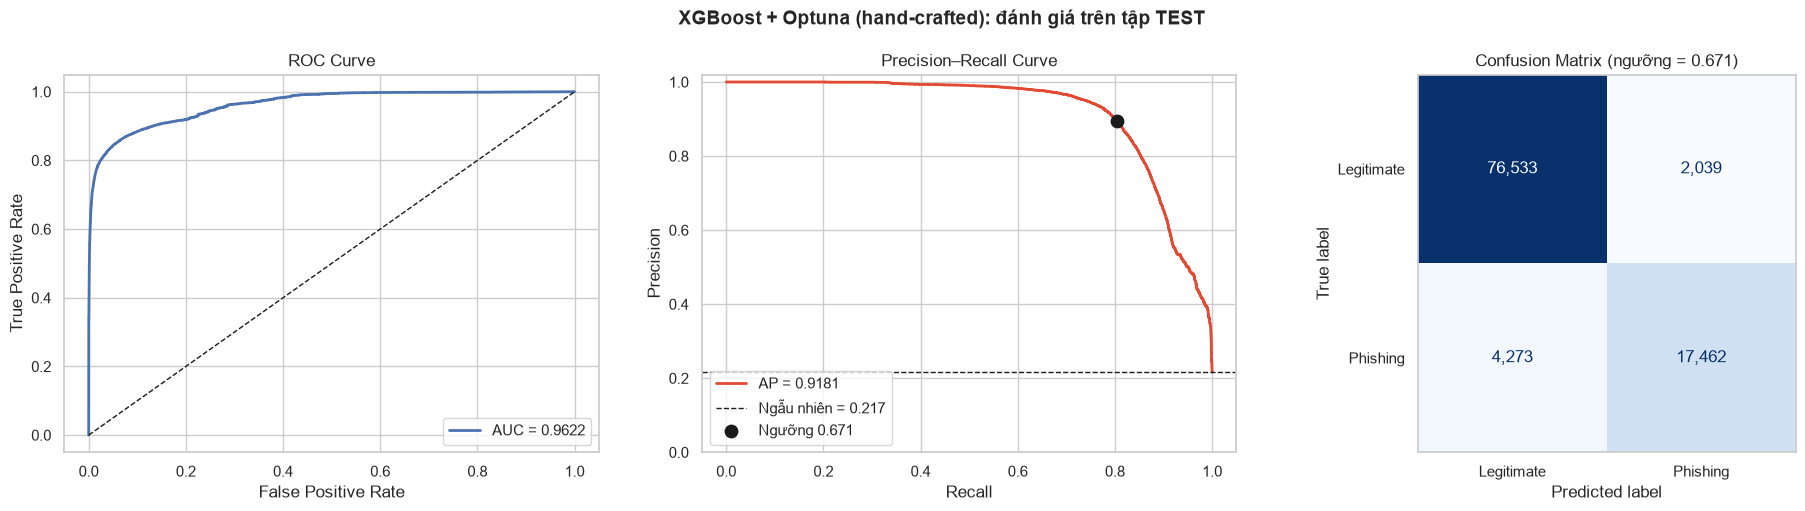

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Recall@FPR≤1%,F1@0.5,FPR,FNR,Threshold
XGBoost + Optuna (hand-crafted),0.9371,0.8954,0.8034,0.8469,0.9622,0.9181,0.7315,0.8214,0.026,0.1966,0.671


In [28]:
NAME_XGB = 'XGBoost + Optuna (hand-crafted)'
t0 = time.time()
xgb_hand = make_xgb(BEST_XGB_PARAMS).fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
print(f'XGBoost train: {time.time() - t0:.1f}s | best_iteration = {xgb_hand.best_iteration}')
p_val_xgb, p_test_xgb = xgb_hand.predict_proba(X_val)[:, 1], xgb_hand.predict_proba(X_test)[:, 1]
evaluate_model(NAME_XGB, p_val_xgb, p_test_xgb)

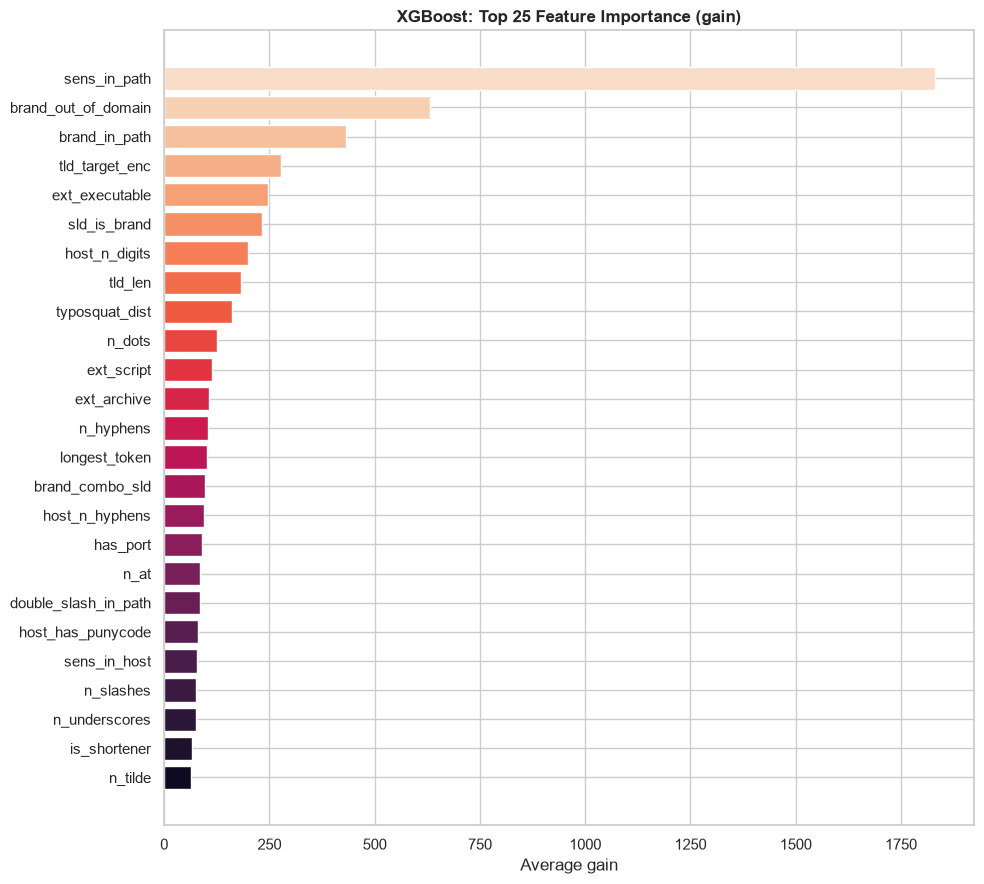

In [29]:
# Feature Importance (gain) của XGBoost
gain = pd.Series(xgb_hand.get_booster().get_score(importance_type='gain')).sort_values(ascending=False)
top = gain.head(25)[::-1]
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top.index, top.values, color=sns.color_palette('rocket', len(top)))
ax.set_xlabel('Average gain')
ax.set_title('XGBoost: Top 25 Feature Importance (gain)', fontweight='bold')
plt.tight_layout()
plt.show()

## 15. Mô hình 4: Stacking Ensemble (TF-IDF LR → XGBoost)

Hai nguồn thông tin bổ sung cho nhau: **TF-IDF LR** nắm bắt mẫu hình chuỗi, còn **đặc trưng thủ công** mã hóa tri thức bảo mật (brand-mismatch, IP, entropy…). Kiến trúc stacking:

1. **Level-0:** sinh điểm `lr_tfidf_score` **out-of-fold (OOF)** cho tập train bằng `StratifiedGroupKFold` (5 fold, nhóm theo domain). Mỗi mẫu train vì vậy được chấm bởi một mô hình **chưa từng thấy domain của nó**, nên tránh được rò rỉ nhãn vào meta-model. Với val/test, điểm này lấy từ LR đã fit trên toàn bộ train (§12).
2. **Level-1 (meta):** XGBoost nhận `đặc trưng thủ công + lr_tfidf_score`, dùng siêu tham số từ Optuna và early stopping trên val.

> Ghi chú: từ vựng/IDF của TF-IDF được fit một lần trên toàn bộ train. Đây là bước không giám sát (không dùng nhãn), nên ảnh hưởng tới OOF là không đáng kể.

In [30]:
t0 = time.time()
oof_lr = np.zeros(len(train_idx), dtype=np.float32)
skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for k, (fit_rel, oof_rel) in enumerate(skf.split(np.zeros(len(train_idx)), y_train, groups_train), 1):
    m = LogisticRegression(C=BEST_C, solver='liblinear', class_weight='balanced', max_iter=300)
    m.fit(T_train[fit_rel], y_train[fit_rel])
    oof_lr[oof_rel] = m.predict_proba(T_train[oof_rel])[:, 1]
    print(f'  Fold {k}: OOF PR-AUC = {average_precision_score(y_train[oof_rel], oof_lr[oof_rel]):.4f}')
print(f'OOF xong trong {time.time() - t0:.1f}s | OOF PR-AUC toàn train = {average_precision_score(y_train, oof_lr):.4f}')

X_train_stack = X_train.assign(lr_tfidf_score=oof_lr)
X_val_stack = X_val.assign(lr_tfidf_score=p_val_lr.astype(np.float32))
X_test_stack = X_test.assign(lr_tfidf_score=p_test_lr.astype(np.float32))

  Fold 1: OOF PR-AUC = 0.8931


  Fold 2: OOF PR-AUC = 0.8488


  Fold 3: OOF PR-AUC = 0.9639


  Fold 4: OOF PR-AUC = 0.9510


  Fold 5: OOF PR-AUC = 0.9734
OOF xong trong 123.8s | OOF PR-AUC toàn train = 0.9223


Meta XGBoost train: 9.6s | best_iteration = 227


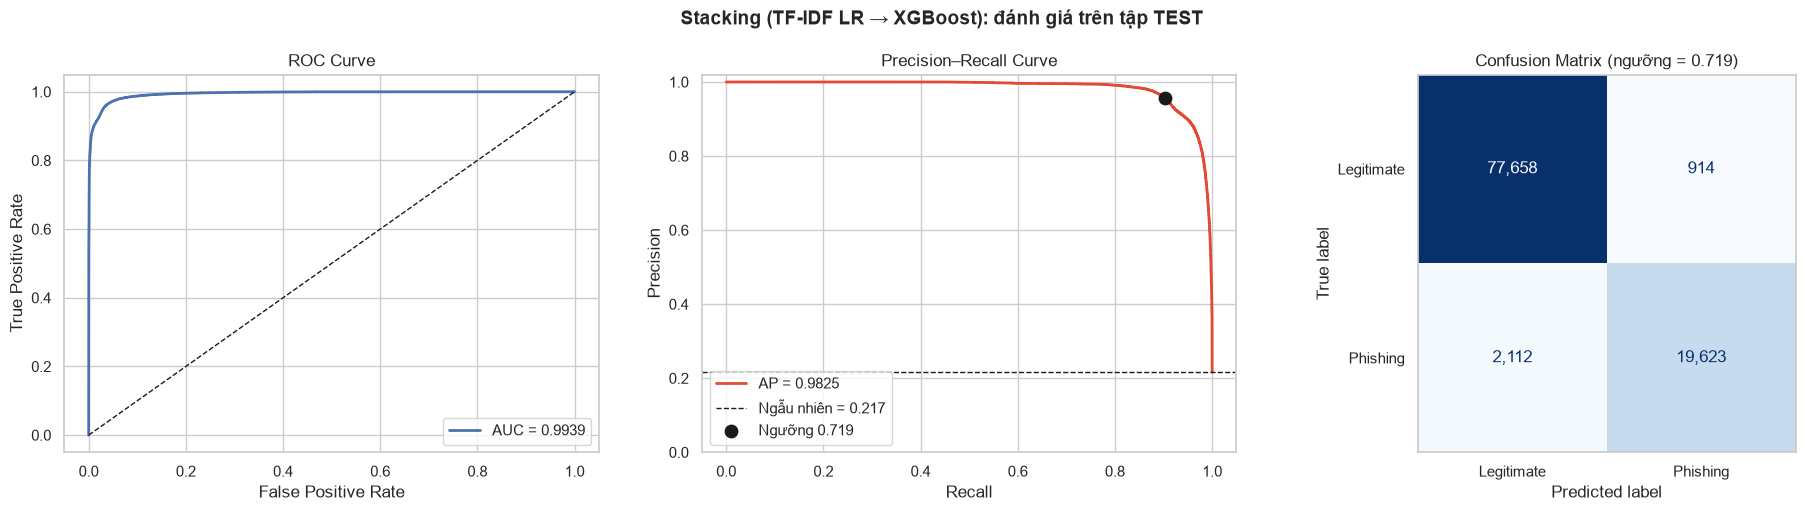

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Recall@FPR≤1%,F1@0.5,FPR,FNR,Threshold
Stacking (TF-IDF LR → XGBoost),0.9698,0.9555,0.9028,0.9284,0.9939,0.9825,0.8978,0.9248,0.0116,0.0972,0.7191


In [31]:
NAME_STACK = 'Stacking (TF-IDF LR → XGBoost)'
t0 = time.time()
xgb_stack = make_xgb(BEST_XGB_PARAMS).fit(X_train_stack, y_train, eval_set=[(X_val_stack, y_val)], verbose=False)
print(f'Meta XGBoost train: {time.time() - t0:.1f}s | best_iteration = {xgb_stack.best_iteration}')
p_val_stack, p_test_stack = xgb_stack.predict_proba(X_val_stack)[:, 1], xgb_stack.predict_proba(X_test_stack)[:, 1]
evaluate_model(NAME_STACK, p_val_stack, p_test_stack)

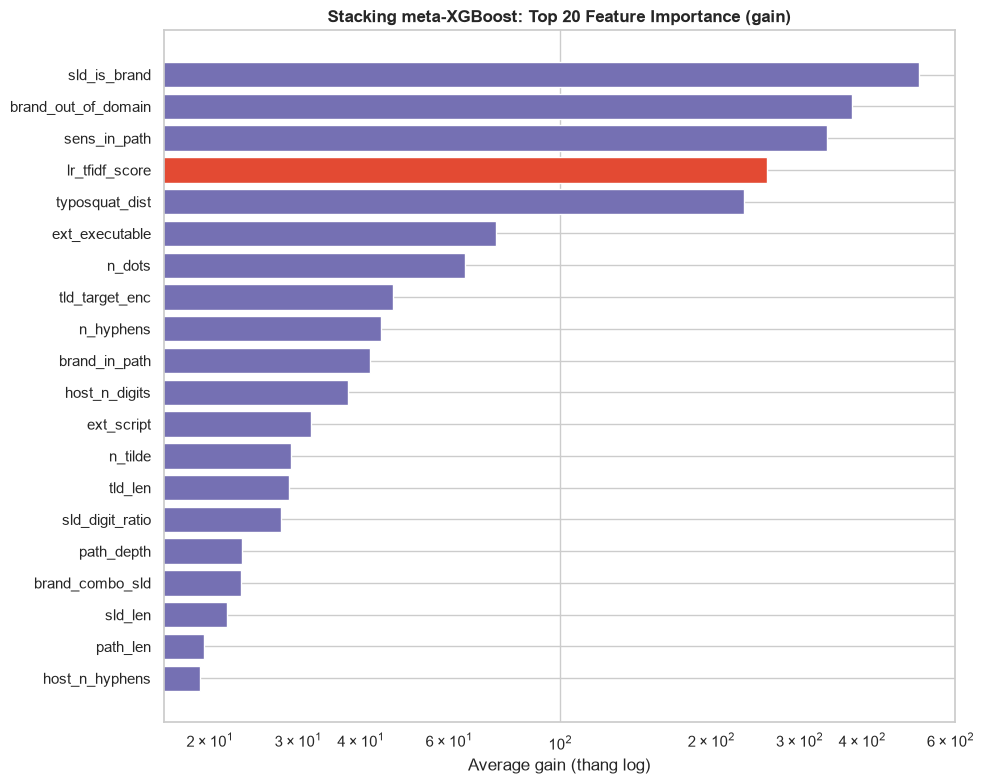

In [32]:
# Feature Importance (gain) của meta-model: đóng góp của điểm TF-IDF so với đặc trưng thủ công
gain_stack = pd.Series(xgb_stack.get_booster().get_score(importance_type='gain')).sort_values(ascending=False)
top = gain_stack.head(20)[::-1]
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top.index, top.values, color=['#e34a33' if c == 'lr_tfidf_score' else '#7570b3' for c in top.index])
ax.set_xscale('log')
ax.set_xlabel('Average gain (thang log)')
ax.set_title('Stacking meta-XGBoost: Top 20 Feature Importance (gain)', fontweight='bold')
plt.tight_layout()
plt.show()

## 16. Mô hình 5: Soft Voting (trung bình có trọng số)

Đây là cách ensemble đơn giản nhất: $p = w \cdot p_{LR} + (1-w) \cdot p_{XGB}$. Trọng số $w$ được chọn trên **validation** theo PR-AUC. Mô hình này đóng vai trò đối chứng, để xem stacking có thực sự tốt hơn phép trung bình hay không.

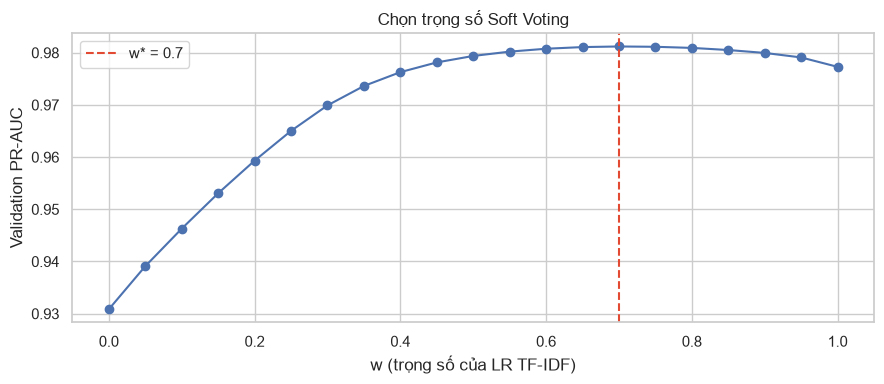

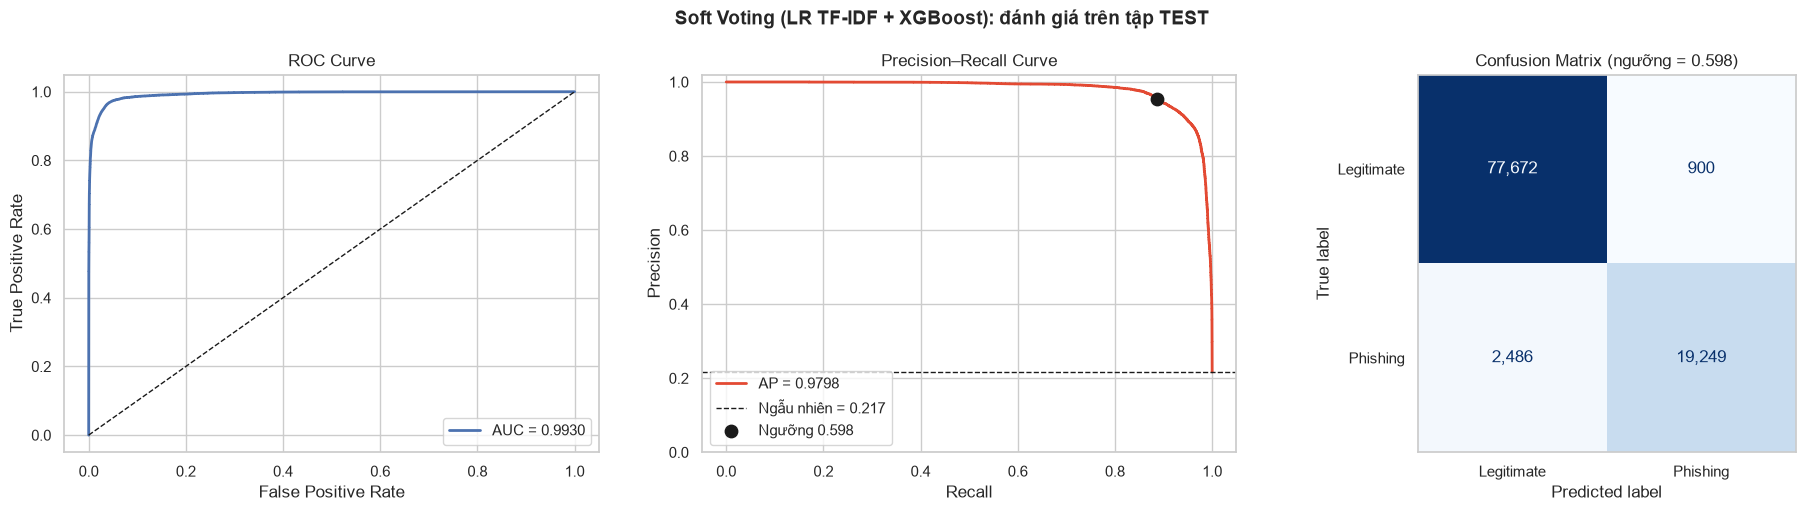

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Recall@FPR≤1%,F1@0.5,FPR,FNR,Threshold
Soft Voting (LR TF-IDF + XGBoost),0.9662,0.9553,0.8856,0.9192,0.993,0.9798,0.8802,0.9232,0.0115,0.1144,0.5979


In [33]:
weights = np.round(np.arange(0, 1.0001, 0.05), 2)
val_ap = [average_precision_score(y_val, w * p_val_lr + (1 - w) * p_val_xgb) for w in weights]
BEST_W = float(weights[int(np.argmax(val_ap))])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weights, val_ap, marker='o')
ax.axvline(BEST_W, ls='--', c='#e34a33', label=f'w* = {BEST_W}')
ax.set(xlabel='w (trọng số của LR TF-IDF)', ylabel='Validation PR-AUC', title='Chọn trọng số Soft Voting')
ax.legend()
plt.tight_layout()
plt.show()

NAME_VOTE = 'Soft Voting (LR TF-IDF + XGBoost)'
evaluate_model(NAME_VOTE, BEST_W * p_val_lr + (1 - BEST_W) * p_val_xgb,
               BEST_W * p_test_lr + (1 - BEST_W) * p_test_xgb)

## 17. So sánh trực quan tất cả mô hình

Phần này chồng ROC và Precision–Recall của mọi mô hình (gồm cả baseline) lên cùng một trục. Panel giữa phóng to vùng **FPR ≤ 5%**, là vùng vận hành thực tế của hệ thống lọc URL, nơi mỗi điểm FPR tương ứng hàng nghìn cảnh báo sai mỗi ngày. Biểu đồ **hiệu chỉnh xác suất (reliability diagram)** cho biết "độ tin cậy" mà mô hình xuất ra có đáng tin hay không.

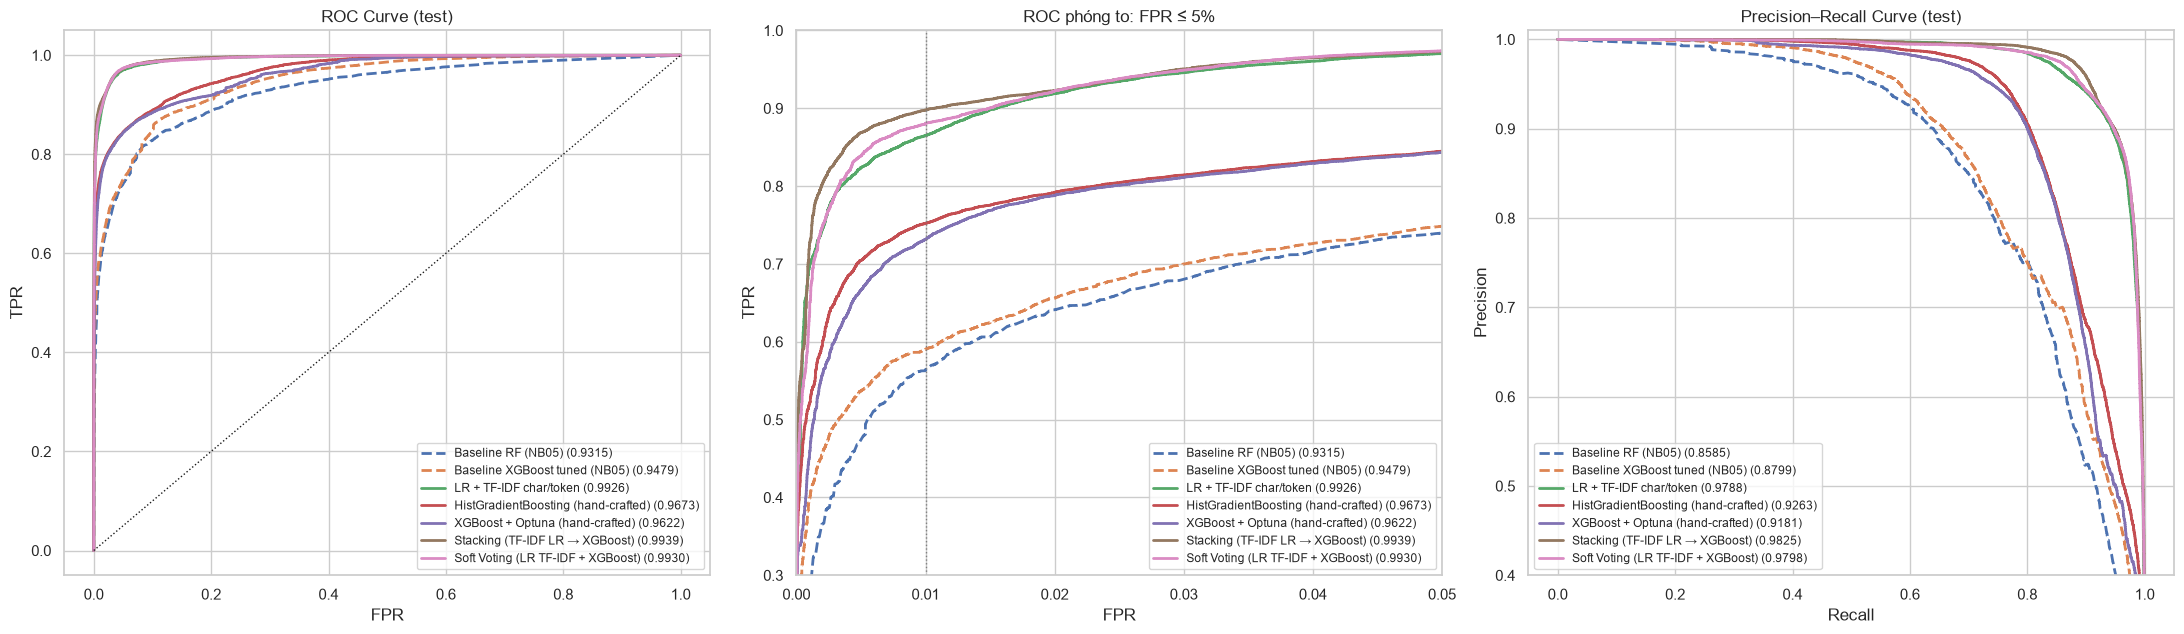

In [34]:
styles = {name: ('--' if RESULTS[name]['Group'].startswith('Baseline') else '-') for name in RESULTS}
fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
for name, (_, p) in PROBAS.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    for ax in axes[:2]:
        ax.plot(fpr, tpr, ls=styles[name], lw=2, label=f'{name} ({RESULTS[name]["ROC-AUC"]:.4f})')
    axes[2].plot(rec, prec, ls=styles[name], lw=2, label=f'{name} ({RESULTS[name]["PR-AUC"]:.4f})')
axes[0].plot([0, 1], [0, 1], 'k:', lw=1)
axes[0].set(title='ROC Curve (test)', xlabel='FPR', ylabel='TPR')
axes[1].set(title='ROC phóng to: FPR ≤ 5%', xlabel='FPR', ylabel='TPR', xlim=(0, 0.05), ylim=(0.3, 1.0))
axes[1].axvline(0.01, c='grey', ls=':', lw=1)
axes[2].set(title='Precision–Recall Curve (test)', xlabel='Recall', ylabel='Precision', ylim=(0.4, 1.01))
for ax, loc in zip(axes, ['lower right', 'lower right', 'lower left']):
    ax.legend(loc=loc, fontsize=8.5)
plt.tight_layout()
plt.show()

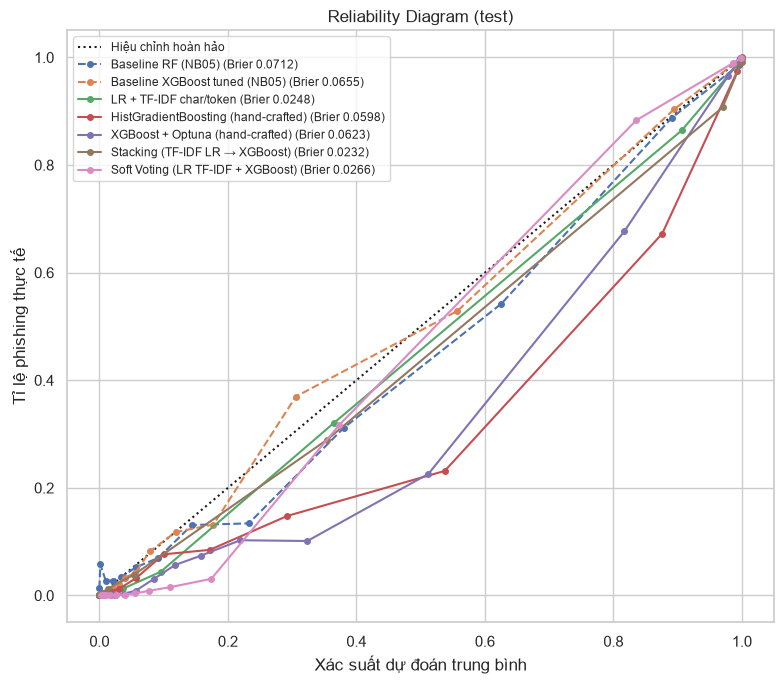

In [35]:
# Reliability diagram: xác suất dự đoán so với tần suất phishing thực tế
fig, ax = plt.subplots(figsize=(8, 7))
ax.plot([0, 1], [0, 1], 'k:', label='Hiệu chỉnh hoàn hảo')
for name, (_, p) in PROBAS.items():
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=15, strategy='quantile')
    ax.plot(mean_pred, frac_pos, marker='o', ms=4, ls=styles[name],
            label=f'{name} (Brier {RESULTS[name]["Brier"]:.4f})')
ax.set(xlabel='Xác suất dự đoán trung bình', ylabel='Tỉ lệ phishing thực tế',
       title='Reliability Diagram (test)')
ax.legend(fontsize=8.5, loc='upper left')
plt.tight_layout()
plt.show()

## 18. Kiểm tra tính bất biến (Invariance Test) và train/serve skew

Đây là phép thử hành vi (behavioral test): **cùng một website viết theo nhiều cách** phải nhận **cùng một xác suất**. Mô hình cũ chấm `google.com` ở mức 96.8% phishing và cho kết quả dao động mạnh theo scheme, `www.` hay dấu `/` cuối. Hàm `predict_all_models()` dưới đây đi qua **đúng pipeline inference** (URL thô → chuẩn hóa → đặc trưng → mô hình).

In [36]:
def predict_all_models(raw_urls) -> pd.DataFrame:
    """Pipeline inference đầy đủ cho URL thô (chưa chuẩn hóa)."""
    raw_urls = list(raw_urls)
    Fn = build_feature_frame(raw_urls)
    Xn = assemble_hand_matrix(Fn, te_tld.transform(Fn[['tld']].astype(object)))
    p_lr = lr_tfidf.predict_proba(vectorize([normalize_url(u) for u in raw_urls]))[:, 1]
    p_xgb = xgb_hand.predict_proba(Xn)[:, 1]
    return pd.DataFrame({
        'URL': raw_urls,
        NAME_BASE_XGB: base_xgb.predict_proba(baseline_feature_frame(raw_urls))[:, 1],
        NAME_LR: p_lr,
        NAME_XGB: p_xgb,
        NAME_STACK: xgb_stack.predict_proba(Xn.assign(lr_tfidf_score=p_lr.astype(np.float32)))[:, 1],
    })


variant_groups = {
    'google':    ['google.com', 'https://google.com', 'www.google.com', 'https://www.google.com/'],
    'wikipedia': ['en.wikipedia.org/wiki/Phishing', 'https://en.wikipedia.org/wiki/Phishing/'],
    'github':    ['github.com/scikit-learn/scikit-learn', 'https://github.com/scikit-learn/scikit-learn'],
    'paypal-phish': ['paypal.com.secure-login.verify-account.xyz/webscr.php?cmd=_login',
                     'http://paypal.com.secure-login.verify-account.xyz/webscr.php?cmd=_login'],
}
extra = ['accounts.google.com/signin', 'paypa1.com/signin', 'http://192.168.10.5/login/paypal/index.php',
         'gobankingrates.com/banking/checking-accounts/', 'ikmbtfomlqp.deliverdarken.ru/start_page.exe']

all_urls = [u for us in variant_groups.values() for u in us] + extra
inv = predict_all_models(all_urls)
model_cols = inv.columns[1:]
display(inv.style.format({c: '{:.3f}' for c in model_cols})
           .background_gradient(subset=list(model_cols), cmap='RdYlGn_r', vmin=0, vmax=1))

# Độ lệch xác suất (max - min) giữa các biến thể của cùng một website: càng gần 0 càng tốt
spread = pd.DataFrame({g: inv.set_index('URL').loc[us, model_cols].agg(lambda s: s.max() - s.min())
                       for g, us in variant_groups.items()}).T
print('Độ lệch xác suất giữa các biến thể của cùng một URL (max − min):')
display(spread.round(3))

,URL,Baseline XGBoost tuned (NB05),LR + TF-IDF char/token,XGBoost + Optuna (hand-crafted),Stacking (TF-IDF LR → XGBoost)
0,google.com,0.968,0.010,0.193,0.028
1,https://google.com,0.817,0.010,0.193,0.028
2,www.google.com,0.980,0.010,0.193,0.028
3,https://www.google.com/,0.193,0.010,0.193,0.028
4,en.wikipedia.org/wiki/Phishing,0.023,0.000,0.153,0.001
5,https://en.wikipedia.org/wiki/Phishing/,0.195,0.000,0.153,0.001
6,github.com/scikit-learn/scikit-learn,0.002,0.158,0.017,0.007
7,https://github.com/scikit-learn/scikit-learn,0.081,0.158,0.017,0.007
8,paypal.com.secure-login.verify-account.xyz/webscr.php?cmd=_login,0.999,1.000,0.999,1.000
9,http://paypal.com.secure-login.verify-account.xyz/webscr.php?cmd=_login,1.000,1.000,0.999,1.000


Độ lệch xác suất giữa các biến thể của cùng một URL (max − min):


,Baseline XGBoost tuned (NB05),LR + TF-IDF char/token,XGBoost + Optuna (hand-crafted),Stacking (TF-IDF LR → XGBoost)
google,0.787,0.0,0.0,0.0
wikipedia,0.173,0.0,0.0,0.0
github,0.079,0.0,0.0,0.0
paypal-phish,0.000,0.0,0.0,0.0


## 19. Bảng tổng hợp metrics và so sánh với baseline

Phần này gồm ba bảng:
1. **Tất cả mô hình trên cùng tập test** (split theo domain): baseline tái lập và mô hình mới.
2. **So sánh trực tiếp:** mức cải thiện (Δ) của từng mô hình mới so với **baseline tốt nhất**.
3. **Đối chiếu với số liệu notebook 05 đã báo cáo.** Các số liệu đó đo trên split *ngẫu nhiên* (có rò rỉ domain) nên lạc quan hơn thực tế, nhưng vẫn được liệt kê để tham chiếu.

In [37]:
METRIC_COLS = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC', 'Recall@FPR≤1%',
               'F1@0.5', 'FPR', 'FNR', 'Brier', 'Threshold', 'FP', 'FN']
results_df = pd.DataFrame(RESULTS).T
results_df = results_df[['Group'] + METRIC_COLS]
results_df[METRIC_COLS] = results_df[METRIC_COLS].astype(float)
results_df = results_df.sort_values(['Group', 'PR-AUC'], ascending=[True, False])
results_df.index.name = 'Model'

higher_better = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC', 'Recall@FPR≤1%', 'F1@0.5']
display(results_df.style
        .format({c: '{:.4f}' for c in METRIC_COLS if c not in ('FP', 'FN')} | {'FP': '{:,.0f}', 'FN': '{:,.0f}'})
        .highlight_max(subset=higher_better, color='#c7e9c0')
        .highlight_min(subset=['FPR', 'FNR', 'Brier', 'FP', 'FN'], color='#c7e9c0')
        .set_caption('Bảng 1: Metrics trên tập TEST (split theo domain); ngưỡng chọn trên validation, baseline dùng 0.5'))

,Group,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Recall@FPR≤1%,F1@0.5,FPR,FNR,Brier,Threshold,FP,FN
Model,,,,,,,,,,,,,,,
Baseline XGBoost tuned (NB05),Baseline (tái lập),0.9114,0.8621,0.7034,0.7747,0.9479,0.8799,0.5904,0.7747,0.0311,0.2966,0.0655,0.5000,"2,445","6,447"
Baseline RF (NB05),Baseline (tái lập),0.9063,0.8153,0.7340,0.7725,0.9315,0.8585,0.5630,0.7725,0.0460,0.2660,0.0712,0.5000,"3,615","5,782"
Stacking (TF-IDF LR → XGBoost),Mô hình mới,0.9698,0.9555,0.9028,0.9284,0.9939,0.9825,0.8978,0.9248,0.0116,0.0972,0.0232,0.7191,914,"2,112"
Soft Voting (LR TF-IDF + XGBoost),Mô hình mới,0.9662,0.9553,0.8856,0.9192,0.9930,0.9798,0.8802,0.9232,0.0115,0.1144,0.0266,0.5979,900,"2,486"
LR + TF-IDF char/token,Mô hình mới,0.9648,0.9512,0.8831,0.9159,0.9926,0.9788,0.8648,0.9229,0.0125,0.1169,0.0248,0.6429,985,"2,541"
HistGradientBoosting (hand-crafted),Mô hình mới,0.9325,0.9740,0.7074,0.8196,0.9673,0.9263,0.7522,0.8186,0.0052,0.2926,0.0598,0.9313,411,"6,359"
XGBoost + Optuna (hand-crafted),Mô hình mới,0.9371,0.8954,0.8034,0.8469,0.9622,0.9181,0.7315,0.8214,0.0260,0.1966,0.0623,0.6710,"2,039","4,273"


In [38]:
baselines = results_df[results_df['Group'].str.startswith('Baseline')]
best_base_name = baselines['PR-AUC'].idxmax()
best_base = baselines.loc[best_base_name]
DELTA_COLS = ['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC', 'Recall@FPR≤1%']

new_models = results_df[~results_df['Group'].str.startswith('Baseline')]
delta = new_models[DELTA_COLS].sub(best_base[DELTA_COLS].astype(float), axis=1)
delta['Giảm FN (%)'] = (1 - new_models['FN'] / best_base['FN']) * 100
delta['Giảm FP (%)'] = (1 - new_models['FP'] / best_base['FP']) * 100
print(f'Baseline tham chiếu: {best_base_name}')
display(delta.style.format('{:+.4f}', subset=DELTA_COLS).format('{:+.1f}%', subset=['Giảm FN (%)', 'Giảm FP (%)'])
             .background_gradient(cmap='Greens', subset=DELTA_COLS)
             .set_caption(f'Bảng 2: Mức cải thiện (Δ) so với {best_base_name}, cùng tập test'))

Baseline tham chiếu: Baseline XGBoost tuned (NB05)


,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Recall@FPR≤1%,Giảm FN (%),Giảm FP (%)
Model,,,,,,,,
Stacking (TF-IDF LR → XGBoost),+0.0934,+0.1994,+0.1537,+0.0461,+0.1025,+0.3074,+67.2%,+62.6%
Soft Voting (LR TF-IDF + XGBoost),+0.0932,+0.1822,+0.1445,+0.0451,+0.0998,+0.2899,+61.4%,+63.2%
LR + TF-IDF char/token,+0.0891,+0.1797,+0.1412,+0.0448,+0.0989,+0.2744,+60.6%,+59.7%
HistGradientBoosting (hand-crafted),+0.1118,+0.0040,+0.0449,+0.0195,+0.0464,+0.1618,+1.4%,+83.2%
XGBoost + Optuna (hand-crafted),+0.0333,+0.1000,+0.0722,+0.0143,+0.0382,+0.1412,+33.7%,+16.6%


In [39]:
# Số liệu notebook 05 đã báo cáo (split NGẪU NHIÊN, ngưỡng 0.5). NB05 không in ROC-AUC/PR-AUC.
# Hàng "XGBoost tuned" lấy từ classification_report (làm tròn 2 chữ số).
reported_nb05 = pd.DataFrame([
    ['[NB05 báo cáo] Logistic Regression', 0.854297, 0.823355, 0.450000, 0.581943],
    ['[NB05 báo cáo] Random Forest',       0.925532, 0.872047, 0.784689, 0.826065],
    ['[NB05 báo cáo] XGBoost (default)',   0.916817, 0.878411, 0.732240, 0.798693],
    ['[NB05 báo cáo] XGBoost tuned',       0.92,     0.89,     0.76,     0.82],
], columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']).set_index('Model')
reported_nb05[['ROC-AUC', 'PR-AUC']] = np.nan
reported_nb05['Split'] = 'Ngẫu nhiên (có rò rỉ domain)'

current = results_df[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC']].copy()
current['Split'] = 'Theo domain (notebook 06)'
comparison = pd.concat([reported_nb05, current])
display(comparison.style.format('{:.4f}', subset=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC'],
                                na_rep='—')
        .set_caption('Bảng 3: Đối chiếu với số liệu notebook 05 đã báo cáo'))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Split
Model,,,,,,,
[NB05 báo cáo] Logistic Regression,0.8543,0.8234,0.4500,0.5819,—,—,Ngẫu nhiên (có rò rỉ domain)
[NB05 báo cáo] Random Forest,0.9255,0.8720,0.7847,0.8261,—,—,Ngẫu nhiên (có rò rỉ domain)
[NB05 báo cáo] XGBoost (default),0.9168,0.8784,0.7322,0.7987,—,—,Ngẫu nhiên (có rò rỉ domain)
[NB05 báo cáo] XGBoost tuned,0.9200,0.8900,0.7600,0.8200,—,—,Ngẫu nhiên (có rò rỉ domain)
Baseline XGBoost tuned (NB05),0.9114,0.8621,0.7034,0.7747,0.9479,0.8799,Theo domain (notebook 06)
Baseline RF (NB05),0.9063,0.8153,0.7340,0.7725,0.9315,0.8585,Theo domain (notebook 06)
Stacking (TF-IDF LR → XGBoost),0.9698,0.9555,0.9028,0.9284,0.9939,0.9825,Theo domain (notebook 06)
Soft Voting (LR TF-IDF + XGBoost),0.9662,0.9553,0.8856,0.9192,0.9930,0.9798,Theo domain (notebook 06)
LR + TF-IDF char/token,0.9648,0.9512,0.8831,0.9159,0.9926,0.9788,Theo domain (notebook 06)


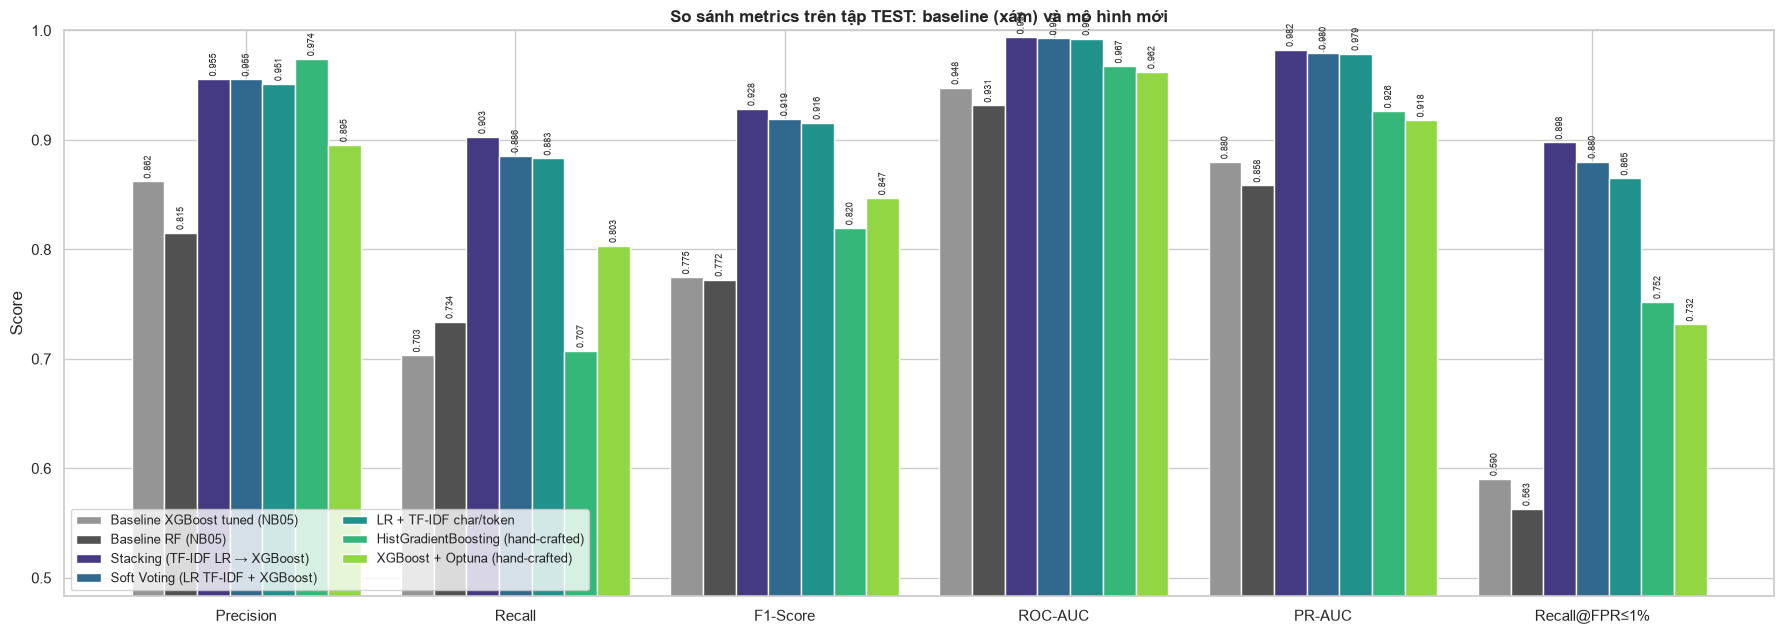

In [40]:
# Biểu đồ so sánh trực quan
plot_cols = ['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC', 'Recall@FPR≤1%']
plot_df = results_df[plot_cols].astype(float)
fig, ax = plt.subplots(figsize=(18, 6.5))
plot_df.T.plot(kind='bar', ax=ax, width=0.85,
               color=sns.color_palette('Greys', 3)[1:] + sns.color_palette('viridis', len(plot_df) - 2))
ax.set_ylim(max(0.0, plot_df.values.min() - 0.08), 1.0)
ax.set_ylabel('Score')
ax.set_title('So sánh metrics trên tập TEST: baseline (xám) và mô hình mới', fontweight='bold')
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='lower left', fontsize=9, ncol=2)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.3f', fontsize=6.5, rotation=90, padding=2)
plt.tight_layout()
plt.show()

## 20. Lưu mô hình và kết quả

Phần này lưu toàn bộ thành phần của pipeline tốt nhất (vectorizer, LR, TargetEncoder, XGBoost, ngưỡng) cùng bảng metrics vào `models/`. Khi nạp lại, cần chạy các cell định nghĩa hàm ở §3, §5 và §7 (`normalize_url`, `build_feature_frame`…) trước khi dự đoán.

> `models/` chứa file nhị phân dung lượng lớn. Nên thêm thư mục này vào `.gitignore`.

In [41]:
if SAVE_ARTIFACTS:
    MODEL_DIR.mkdir(exist_ok=True)
    for vec in (char_vec, word_vec):            # bỏ danh sách n-gram bị lọc (rất lớn, không cần cho inference)
        if hasattr(vec, 'stop_words_'):
            try:
                delattr(vec, 'stop_words_')
            except AttributeError:
                pass
    artifacts = {
        'char_vec': char_vec, 'word_vec': word_vec, 'lr_tfidf': lr_tfidf, 'te_tld': te_tld,
        'xgb_hand': xgb_hand, 'xgb_stack': xgb_stack, 'hgb': hgb,
        'num_cols': NUM_COLS, 'hand_cols': HAND_COLS,
        'thresholds': {name: RESULTS[name]['Threshold'] for name in RESULTS},
        'soft_voting_weight': BEST_W, 'xgb_params': BEST_XGB_PARAMS, 'lr_C': BEST_C,
    }
    path = MODEL_DIR / 'phishing_url_models_v2.joblib'
    joblib.dump(artifacts, path, compress=3)
    results_df.to_csv(MODEL_DIR / 'metrics_v2_test.csv')
    comparison.to_csv(MODEL_DIR / 'metrics_v2_vs_nb05.csv')
    print(f'Đã lưu: {path} ({path.stat().st_size / 1e6:.1f} MB) và các file metrics CSV.')

Đã lưu: /Users/buiquanghuy/Documents/phishing-url-detection/models/phishing_url_models_v2.joblib (13.0 MB) và các file metrics CSV.


## 21. Kết luận

> Các con số dưới đây lấy từ lần chạy với `RANDOM_STATE = 42`. Nếu chạy lại với cấu hình khác, hãy đối chiếu với Bảng 1–3 ở §19.

### 21.1. Mức cải thiện so với baseline (cùng tập test, split theo domain)

| Chỉ số | Baseline XGBoost tuned (NB05) | **Stacking (TF-IDF LR → XGBoost)** | Δ |
|---|:-:|:-:|:-:|
| Accuracy | 0.9114 | **0.9698** | +0.058 |
| Precision | 0.8621 | **0.9555** | +0.093 |
| Recall | 0.7034 | **0.9028** | +0.199 |
| F1-Score | 0.7747 | **0.9284** | **+0.154** |
| ROC-AUC | 0.9479 | **0.9939** | +0.046 |
| PR-AUC | 0.8799 | **0.9825** | +0.103 |
| Recall @ FPR ≤ 1% | 0.5904 | **0.8978** | +0.307 |
| Số False Negative (bỏ sót) | 6,447 | **2,112** | **−67.2%** |
| Số False Positive (báo nhầm) | 2,445 | **914** | **−62.6%** |

Ngay cả khi đối chiếu với con số **lạc quan** mà notebook 05 báo cáo trên split ngẫu nhiên có rò rỉ domain (RF: F1 0.826), mô hình mới vẫn cao hơn **+0.10 F1**, dù được đánh giá theo giao thức khắt khe hơn nhiều.

### 21.2. Nhận định chính

1. **Biểu diễn đặc trưng là đòn bẩy lớn nhất, đúng như báo cáo phân tích đã chỉ ra.** Chỉ riêng Logistic Regression trên TF-IDF char n-gram đã đạt F1 0.916 và PR-AUC 0.979. Mô hình tuyến tính đơn giản này vượt xa mọi mô hình cây trên đặc trưng đếm.
2. **Đặc trưng thủ công mới có giá trị thật:** cùng thuật toán XGBoost, việc thay 20 đặc trưng cũ bằng ~60 đặc trưng mới nâng F1 từ 0.775 lên 0.847. Các cờ `host_is_ip`, `ext_executable`, `double_slash_in_path`, `is_shortener`, `brand_combo_sld`, `brand_out_of_domain` đều có tỉ lệ phishing trên 90% khi bật (§8).
3. **Stacking > Soft Voting > từng mô hình đơn lẻ:** hai nguồn thông tin (chuỗi ký tự và tri thức bảo mật) bổ sung cho nhau. Meta-learner học được *khi nào* nên tin điểm TF-IDF, nên giảm thêm 17% FN so với LR TF-IDF đơn lẻ (2,541 → 2,112).
4. **Đã sửa train/serve skew:** độ lệch xác suất giữa các biến thể `google.com` / `https://www.google.com/` giảm từ **0.787 xuống 0.000**. `google.com` không còn bị gắn nhãn phishing (0.968 → 0.028). URL malware DGA `ikmbtfomlqp.deliverdarken.ru/start_page.exe`, trước đây bị bỏ sót (0.166), nay được phát hiện (1.000).
5. **Ngưỡng chọn trên validation phát huy tác dụng:** ngưỡng tối ưu của các mô hình mới nằm trong khoảng 0.60–0.93, không phải 0.5. Lý do là `class_weight` / `scale_pos_weight` làm dịch phân phối xác suất.

### 21.3. Hạn chế còn lại (đánh giá trung thực)

- **Thiên lệch nhãn của dataset vẫn còn:** trong dữ liệu, `login`/`signin` có 99.5% là phishing. Vì vậy LR TF-IDF chấm `accounts.google.com/signin` ở mức 0.999. Stacking giảm điểm này xuống 0.142 nhờ đặc trưng `sld_is_brand`, nhưng gốc rễ nằm ở dữ liệu. `gobankingrates.com/banking/...` vẫn là False Positive (0.78).
- **Dataset cũ, đơn nguồn (Kaggle):** để triển khai thực tế cần bổ sung dữ liệu mới, ví dụ phishing từ PhishTank/OpenPhish/URLhaus và URL hợp lệ có ý nghĩa thống kê (danh sách Tranco), rồi đánh giá theo **thời gian** (temporal split).
- **Xác suất chưa được hiệu chỉnh:** reliability diagram (§17) cho thấy các mô hình dùng trọng số lớp bị lệch xác suất. Nếu cần hiển thị "độ tin cậy" cho người dùng, nên thêm bước `CalibratedClassifierCV(method='isotonic')` trên một tập calibration riêng.
- **Độ biến thiên giữa các fold OOF (PR-AUC 0.85–0.97):** hiệu năng phụ thuộc đáng kể vào domain nào rơi vào tập đánh giá, nên khi báo cáo cần kèm khoảng tin cậy (bootstrap).

### 21.4. Hướng phát triển tiếp (vẫn trong phạm vi ML truyền thống)

- Thử **LightGBM / CatBoost** (CatBoost xử lý TLD categorical trực tiếp) khi môi trường cho phép cài đặt.
- Hiệu chỉnh xác suất bằng isotonic, và chọn ngưỡng theo **ma trận chi phí** của từng kịch bản (email gateway so với cảnh báo SOC).
- Lọc bớt các cặp đặc trưng tương quan |ρ| ≥ 0.9 (§9), rồi đánh giá lại bằng SHAP / permutation importance.
- Đóng gói `normalize_url` + `build_feature_frame` thành module trong `src/` và viết unit test cho các bất biến ở §18.